# Optimizing document review agents for cost and quality: decision models vs LLMs

This notebook measures a baseline document review agent, changes one thing per round, and accepts the savings only if quality holds. It also asks which steps should be a decision model and which still need an LLM. The default run is an offline simulation on synthetic pages; optional live cells use real APIs under a $1 budget.

### The optimization loop

```mermaid
flowchart LR
    A["Version 1"] --> B["Traces"] --> C["Find errors"] --> D["Build evals"] --> E["Tune"] --> F["Climb"]
    F -.-> C
```

*Follow the arrows left to right; the dashed arrow is why we never stop after one round.*

## Outline

1. Success criteria and a small eval set.
2. An intentionally inefficient baseline agent.
3. Baseline cost, tokens, quality, latency, tool calls and leaks.
4. Round 1: prompt, output, tool and context controls.
5. Round 2: route routine pages to a smaller model.
6. Round 3: a decision model (Decisions API) plus a code router.
7. Round 4: prompt caching.
8. Round 5: split real-time and background work.
9. Human-in-the-loop attorney review.
10. Tradeoffs and operating scenarios, including decision models vs LLMs.
11. Monitoring, evals and guardrails.

## Use case

Fictional matter: *Hollis v. Arcadia Freight*. The agent sees one page and picks one outcome: **produce**, **withhold**, **redact** or **attorney review**.

Never acceptable: a **privileged** page produced, or **personal data** left in produced text.

Five mock tools stand in for real systems: custodian directory, review protocol, prior productions, redaction and attorney escalation. The baseline is one `gpt-6.1-terra` agent that does everything, expensively, on purpose.

Models: `gpt-6.1-terra` (strongest tier), `gpt-6-luna` (small tier) and the Decisions API, which runs on `gpt-6-luna`. Reasoning is off for every Responses call (`reasoning={"effort": "none"}`), so it is not a knob here.

## Setup

Use Python 3.13, then install and open the notebook:

```bash
uv sync --group notebook
uv run jupyter lab
```

Nothing calls an API by default. To opt in, set these in `.env` (git-ignored) or the environment:

```bash
export OPENAI_API_KEY=...
export LANGSMITH_API_KEY=...        # only for tracing
export RUN_LIVE_API_CALLS=true      # live agent, Decisions and engine-comparison cells
export RUN_LLM_JUDGE=true           # optional answer judge (gpt-6.1-terra)
export LANGSMITH_TRACING=true       # send traces for the live runs to LangSmith
```

Environment values win over `.env`. All live cells share one `BudgetTracker` with a hard $1 stop (limit in `config.toml`). Leave the flags unset for a fully offline run. The Batch example only writes a local file under `outputs/`; it never submits.

### How the notebook runs

```mermaid
flowchart LR
    S["Offline simulation<br/>default, free"] --> T["Trace table"]
    L["Live cells<br/>RUN_LIVE_API_CALLS<br/>1 dollar budget, LangSmith traces"] --> T
    T --> C["Tables and charts"]
```

*Both paths fill the same trace table, so every table and chart below works either way.*

In [1]:
%matplotlib inline
import inspect
import json
import os
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from IPython.display import Markdown, display
from openai import AsyncOpenAI

load_dotenv(override=False)


def env_flag(name):
    return os.environ.get(name, "false").lower() == "true"


RUN_LIVE_API_CALLS = env_flag("RUN_LIVE_API_CALLS")
RUN_LLM_JUDGE = env_flag("RUN_LLM_JUDGE")
LANGSMITH_TRACING = env_flag("LANGSMITH_TRACING")
if (RUN_LIVE_API_CALLS or RUN_LLM_JUDGE) and not os.environ.get("OPENAI_API_KEY"):
    raise RuntimeError("Set OPENAI_API_KEY before enabling the live agent or judge.")
if LANGSMITH_TRACING and not os.environ.get("LANGSMITH_API_KEY"):
    raise RuntimeError("Set LANGSMITH_API_KEY before enabling LangSmith tracing.")
os.environ["LANGSMITH_TRACING"] = str(LANGSMITH_TRACING).lower()
os.environ["LANGCHAIN_TRACING_V2"] = str(LANGSMITH_TRACING).lower()
os.environ.setdefault("LANGSMITH_PROJECT", "doc-review-opt")

from doc_review_opt.config import get_settings
from doc_review_opt.live_api import LIVE_PAGE_LIMIT, BudgetTracker

LIVE = get_settings().live
client = AsyncOpenAI(timeout=LIVE.timeout_s, max_retries=LIVE.max_retries) if RUN_LIVE_API_CALLS else None
judge_client = AsyncOpenAI(timeout=LIVE.timeout_s, max_retries=LIVE.max_retries) if RUN_LLM_JUDGE else None
budget = BudgetTracker()
OUTPUT_DIR = Path(os.environ.get("DOC_REVIEW_OUTPUT_DIR", "../outputs"))

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", None)
print("RUN_LIVE_API_CALLS =", RUN_LIVE_API_CALLS)
print("RUN_LLM_JUDGE =", RUN_LLM_JUDGE)
print("LANGSMITH_TRACING =", LANGSMITH_TRACING)
print(f"Live budget hard stop: ${budget.limit_usd:.2f}; live page limit: {LIVE_PAGE_LIMIT}")

RUN_LIVE_API_CALLS = False
RUN_LLM_JUDGE = False
LANGSMITH_TRACING = False
Live budget hard stop: $1.00; live page limit: 6


## Success criteria

Accept savings only if quality holds. The gates, in order:

1. **Hard gates:** no privileged page produced, no personal data left in produced text.
2. **Quality:** the right outcome per page.
3. **Escalation accuracy:** attorney review only where needed.
4. **Cost and latency:** compared only after the gates pass. Cost includes attorney time.

The eval set has 30 pages, split into a calibration half and a holdout half. Thresholds are tuned on the calibration half only.

## Simulation contract

The default path uses synthetic pages and modeled metrics. Its numbers are **not a production benchmark**.

- **Real:** the LangGraph review graph, the router and the guardrail checks.
- **Modeled:** token counts, latency, cache hits and quality score, from illustrative formulas and the prices in `config.toml`.
- **Assumed:** each engine's *ambiguity profile* (how sharp its probabilities are and where it errs).
- **Fixture-labelled:** tool selection, so tool choice is not measured.

The optional live cells produce the same trace schema from real API calls.

## Optimization knobs

| Knob | Inefficient baseline | Optimized pattern | Primary metric |
|---|---|---|---|
| Prompt and output | "Be thorough" instructions, `verbosity="high"`, free-text answer | Specific rules, a strict `json_schema` disposition, `verbosity="low"`, capped output | Output tokens, parse failures |
| Tool surface | All five tools exposed, `tool_choice="required"` | Full stable tool list plus `allowed_tools` per page type | Tool calls, unnecessary tools |
| Tool schemas and payloads | Verbose descriptions, audit logs and directories in every result | Small schemas and slim payloads with only decision-critical fields | Input tokens |
| Model routing | One `gpt-6.1-terra` agent for every page | `gpt-6-luna` triage and routine pages; `gpt-6.1-terra` for privileged and borderline pages | Cost, latency, escalation accuracy |
| **Decisions vs LLM** | An LLM agent decides every page, then explains itself | One Decisions call (score `responsive`, predicates `privileged` and `contains_pii`) plus a code router; an LLM only for redaction text and a second opinion on the ambiguous band | Cost, latency, typed routing, calibration effort |
| Prompt caching | Volatile page text mixed into the prefix | Stable protocol first, page last, a `prompt_cache_key` per matter | Cached input tokens, cost |
| Workflow split | Privilege-log draft, QA and production tags in the review path | Review path sync; the rest as Batch jobs at 50% off | p50 latency, synchronous cost |
| Guardrails and evals | Informal spot checks | Deterministic checks plus a judge schema for live traces | Regression rate, safety pass rate |

Reasoning is off everywhere, so it is not a row here.

## Sample evaluation set

30 synthetic pages: the six original pages plus borderline responsiveness, attorney-cc'd business mail, several personal-data kinds, OCR noise and near-duplicates. Each page is labelled for responsiveness (0 to 2), privilege, personal data, expected route, escalation, difficulty and risk.

In [2]:
from doc_review_opt.review_agent import CALIBRATION, EVAL_SET, HOLDOUT, MATTER

eval_table = pd.DataFrame(
    {
        "doc_id": page.doc_id,
        "custodian": page.custodian,
        "difficulty": page.labels.difficulty,
        "risk": page.labels.risk,
        "responsive_level": page.labels.responsive_level,
        "privileged": page.labels.privileged,
        "contains_pii": page.labels.contains_pii,
        "expected_route": page.labels.expected_route,
        "must_escalate": page.labels.must_escalate,
        "expected_tools": ", ".join(page.labels.expected_tools),
    }
    for page in EVAL_SET
)
print(f"{MATTER}: {len(EVAL_SET)} pages ({len(CALIBRATION)} calibration, {len(HOLDOUT)} holdout)")
display(eval_table.head(10))
display(eval_table.groupby(["expected_route", "difficulty"]).size().rename("pages").to_frame())

24-CV-118 (Hollis v. Arcadia Freight): 30 pages (16 calibration, 14 holdout)


,doc_id,custodian,difficulty,risk,responsive_level,privileged,contains_pii,expected_route,must_escalate,expected_tools
0,ARC-000141,Dana Whitfield,simple,low,2,False,False,produce,False,
1,ARC-000163,Dana Whitfield,simple,low,2,False,False,produce,False,
2,ARC-000212,Ines Calloway,simple,low,0,False,False,withhold,False,
3,ARC-000245,Grace Lindqvist,simple,low,0,False,False,withhold,False,
4,ARC-000259,Grace Lindqvist,simple,medium,0,False,True,withhold,False,
5,ARC-000284,Dana Whitfield,simple,high,2,True,False,attorney_review,True,"lookup_custodian, escalate_to_attorney"
6,ARC-000289,Yusuf Demir,simple,low,2,False,False,produce,False,
7,ARC-000299,Dana Whitfield,simple,high,2,True,False,attorney_review,True,"lookup_custodian, escalate_to_attorney"
8,ARC-000306,Dana Whitfield,trap,medium,2,False,False,produce,False,lookup_custodian
9,ARC-000318,Ines Calloway,simple,low,0,False,False,withhold,False,


pages
expected_route  difficulty       
attorney_review borderline      4
                simple          5
                trap            1
produce         simple          5
                trap            4
redact          routine         1
                simple          4
withhold        simple          5
                trap            1

**How to read it.** Left: how many pages each route should end in. Right: how hard the pages are.

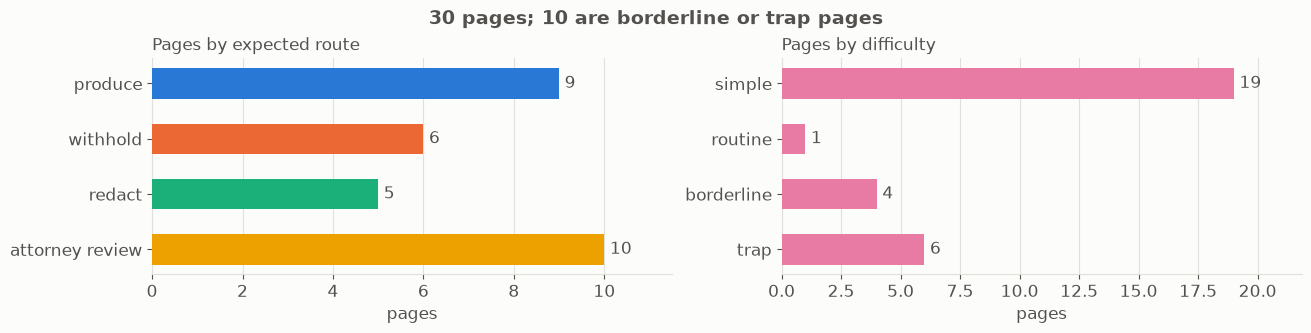

In [3]:
from doc_review_opt.reporting import plot_eval_set

display(plot_eval_set(eval_table))

## Support data and tools

Five local functions in `review_agent.py` stand in for the matter's systems. The baseline returns oversized payloads; later rounds return only decision-critical fields. The next cell shows one slim custodian record.

In [4]:
from doc_review_opt.review_agent import ATTORNEYS, lookup_custodian

print(json.dumps(lookup_custodian(ATTORNEYS[0], payload="slim"), indent=2))

{
  "found": true,
  "name": "Priya Raghunathan",
  "is_attorney": true
}


In [5]:
from doc_review_opt.pricing import approx_tokens
from doc_review_opt.review_agent import SLIM_TOOLS, VERBOSE_TOOLS

print("Verbose custodian payload tokens:", approx_tokens(lookup_custodian(ATTORNEYS[0], payload="verbose")))
print("Slim custodian payload tokens:", approx_tokens(lookup_custodian(ATTORNEYS[0], payload="slim")))
print("Verbose tool schema tokens:", approx_tokens(VERBOSE_TOOLS))
print("Slim tool schema tokens:", approx_tokens(SLIM_TOOLS))

Verbose custodian payload tokens: 2171
Slim custodian payload tokens: 17
Verbose tool schema tokens: 537
Slim tool schema tokens: 393


## Baseline architecture

The baseline does too much in one synchronous path.

```mermaid
flowchart LR
    P["Page"] --> A["One terra super-agent<br/>everything runs synchronously"]
    A <--> T["All 5 tools<br/>verbose payloads"]
    A --> F["Free-text answer"]
    A --> L["Privilege log<br/>QA<br/>production tags"]
    F --> O["Parse the text into a route"]
    classDef before fill:#e1e0d9,stroke:#52514e,stroke-width:1px,color:#1a1a18
```

*Look at the single box doing every job: that is the cost and latency we will take apart.*

### The review graph

Every variant runs through the same LangGraph graph. A `Send` fans pages out to one subgraph each; every page is classified, routed in code and ends in one terminal node. `attorney_review` pauses with `interrupt()`. Only IDs and scores cross that boundary, never page text.

```mermaid
flowchart LR
    P["Page"] --> D["Decisions classify<br/>3 questions"]
    D --> R["Code router"]
    R -->|"privilege above 0.2"| A["Attorney review"]:::attorney
    R -->|"responsive below 0.5"| W["Withhold"]:::withhold
    R -->|"ambiguous band<br/>0.5 to 1.5"| T["gpt-6.1-terra<br/>second opinion"]
    T -->|"still unsure"| A
    T -->|"clear"| U["Produce"]:::produce
    R -->|"PII above 0.5"| X["Redact"]:::redact
    R -->|"otherwise"| U
    classDef produce fill:#2a78d6,stroke:#52514e,stroke-width:1px,color:#1a1a18
    classDef withhold fill:#eb6834,stroke:#52514e,stroke-width:1px,color:#1a1a18
    classDef redact fill:#1baf7a,stroke:#52514e,stroke-width:1px,color:#1a1a18
    classDef attorney fill:#eda100,stroke:#52514e,stroke-width:1px,color:#1a1a18
```

*Follow one page: three typed answers go in, plain code picks one of four outcomes.*

In [6]:
from doc_review_opt.decisions import RoutingPolicy
from doc_review_opt.graph import build_review_graph, review_checkpointer
from doc_review_opt.simulation import build_simulated_engines
from doc_review_opt.variants import CALIBRATED_POLICY, DECISION_MODEL, VARIANTS

graph_classifier, graph_redactor = build_simulated_engines(
    VARIANTS[DECISION_MODEL], EVAL_SET, CALIBRATED_POLICY
)
review_graph = build_review_graph(
    graph_classifier, graph_redactor, review_checkpointer(), policy=CALIBRATED_POLICY
)
print("Graph nodes:", ", ".join(review_graph.get_graph(xray=True).nodes))

Graph nodes: __start__, __end__, review_page:classify, review_page:attorney_review, review_page:redact, review_page:produce, review_page:withhold, review_page:__end__


## Metrics helpers

The helpers read token usage from each response, including cached tokens. Output tokens already include reasoning tokens (none here).

Prices below are USD per million tokens, verified November 18, 2026. Decisions has the same input price as `gpt-6-luna`, **Decisions output is not charged**, and Batch is 50% off. Long-context and priority pricing are not covered.

In [7]:
from doc_review_opt.config import get_settings
from doc_review_opt.pricing import BATCH_DISCOUNT, MODEL_PRICES_USD_PER_1M

display(pd.DataFrame(MODEL_PRICES_USD_PER_1M).T.rename_axis("model"))
print(f"Batch multiplier: {BATCH_DISCOUNT} (50% off)")
print(f"Attorney review assumption: ${get_settings().attorney.review_cost_usd_per_page:.2f} per escalated page")

,input,cached_input,cache_write,output
model,,,,
gpt-6.1-terra,1.0,0.05,1.250,5.0
gpt-6-luna,0.1,0.01,0.125,0.5
decisions:gpt-6-luna,0.1,0.01,0.125,0.0


Batch multiplier: 0.5 (50% off)
Attorney review assumption: $1.50 per escalated page


## Dry-run simulation

The [simulation](../src/doc_review_opt/simulation.py) runs each variant on the same 30 pages through the review graph with simulated engines, so routing can really err. Cost is model cost plus attorney time per escalated page.

- Decision-model rounds use thresholds calibrated on the calibration half.
- Caching assumes a warm cache and the 1,024-token minimum; it is not measured.
- Round 5 removes background work from synchronous latency but still counts its cost.
- `03a_router_only` (Decisions plus code router, no second opinion) is the "Decisions only" arm.

In [8]:
from doc_review_opt.simulation import simulate_all
from doc_review_opt.traces import traces_frame
from doc_review_opt.variants import EXTRA_VARIANTS, VARIANT_ORDER

traces = await simulate_all(include_extras=True)
frame = traces_frame(traces)
frame.drop(columns="produced_text").head()

,variant,variant_label,mode,doc_id,difficulty,risk,engine,models_used,routing_tokens,tool_calls,expected_tools,tools,route,route_reason,expected_route,decision,expected_disposition,escalated,must_escalate,attorney_decision,...,reasoning_tokens,sync_tokens,background_tokens,total_tokens,latency_s,sync_cost_usd,background_cost_usd,model_cost_usd,attorney_cost_usd,cost_usd,privileged_leak,pii_leak,route_correct,escalation_correct,unnecessary_escalation,responsive_withheld,extra_tool_calls,parse_failed,quality_score,policy_compliant
0,00_bad_baseline,Bad baseline,simulated,ARC-000141,simple,low,agent,gpt-6.1-terra,0,5,,"lookup_custodian, lookup_protocol, check_prior_production, apply_redactions, escalate_to_attorney",produce,agent_disposition,produce,produce,produce,False,False,NaN,...,0,6491,0,6491,3.176603,0.007011,0.0,0.007011,0.0,0.007011,False,False,True,True,False,False,5,False,0.85,True
1,00_bad_baseline,Bad baseline,simulated,ARC-000163,simple,low,agent,"gpt-6.1-terra, gpt-6-luna",0,5,,"lookup_custodian, lookup_protocol, check_prior_production, apply_redactions, escalate_to_attorney",attorney_review,agent_disposition,produce,produce,produce,True,False,produce,...,0,8886,0,8886,4.109872,0.009257,0.0,0.009257,1.5,1.509257,False,False,False,False,True,False,5,True,0.36,False
2,00_bad_baseline,Bad baseline,simulated,ARC-000212,simple,low,agent,gpt-6.1-terra,0,5,,"lookup_custodian, lookup_protocol, check_prior_production, apply_redactions, escalate_to_attorney",withhold,agent_disposition,withhold,withhold,withhold,False,False,NaN,...,0,8624,0,8624,3.586936,0.009148,0.0,0.009148,0.0,0.009148,False,False,True,True,False,False,5,False,0.85,True
3,00_bad_baseline,Bad baseline,simulated,ARC-000245,simple,low,agent,gpt-6.1-terra,0,5,,"lookup_custodian, lookup_protocol, check_prior_production, apply_redactions, escalate_to_attorney",withhold,agent_disposition,withhold,withhold,withhold,False,False,NaN,...,0,8628,0,8628,3.587705,0.009152,0.0,0.009152,0.0,0.009152,False,False,True,True,False,False,5,False,0.85,True
4,00_bad_baseline,Bad baseline,simulated,ARC-000259,simple,medium,agent,gpt-6.1-terra,0,5,,"lookup_custodian, lookup_protocol, check_prior_production, apply_redactions, escalate_to_attorney",withhold,agent_disposition,withhold,withhold,withhold,False,False,NaN,...,0,8617,0,8617,3.585590,0.009141,0.0,0.009141,0.0,0.009141,False,False,True,True,False,False,5,False,0.85,True


## Summary

One row per variant. `blended_cost_per_verified_page` is model cost plus attorney cost, divided by correctly dispositioned pages.

In [9]:
from doc_review_opt.reporting import summarize

full_summary = summarize(frame)
summary = full_summary[full_summary["variant"].isin(VARIANT_ORDER)].reset_index(drop=True)

USD_FORMATS = {
    "model_cost_per_page_usd": "${:.5f}",
    "cost_per_page_usd": "${:.3f}",
    "blended_cost_per_verified_page": "${:.3f}",
    "monthly_model_cost_at_100k_pages": "${:,.0f}",
    "monthly_cost_at_100k_pages": "${:,.0f}",
}
FORMATS = {
    "mean_quality": "{:.2f}",
    "policy_compliance": "{:.0%}",
    "route_accuracy": "{:.0%}",
    "escalation_accuracy": "{:.0%}",
    "escalation_rate": "{:.0%}",
    "privileged_leaks": "{:d}",
    "pii_leaks": "{:d}",
    "mean_tool_calls": "{:.1f}",
    "mean_extra_tool_calls": "{:.1f}",
    "mean_sync_tokens": "{:,.0f}",
    "mean_total_tokens": "{:,.0f}",
    "mean_cached_tokens": "{:,.0f}",
    "p50_latency_s": "{:.2f}",
    "sync_cost_per_page_usd": "${:.6f}",
    "background_cost_per_page_usd": "${:.6f}",
    "cost_reduction_vs_baseline": "{:.0%}",
    "mean_sync_tokens_delta_vs_previous": "{:+,.0f}",
    "mean_total_tokens_delta_vs_previous": "{:+,.0f}",
    "p50_latency_s_delta_vs_previous": "{:+.2f}",
    "model_cost_per_page_usd_delta_vs_previous": "${:+.5f}",
    "cost_per_page_usd_delta_vs_previous": "${:+.3f}",
    "quality_delta_vs_previous": "{:+.2f}",
    **USD_FORMATS,
}


def show(table):
    display(table.style.format(FORMATS, na_rep="-"))


show(
    summary[
        [
            "variant_label",
            "mean_quality",
            "policy_compliance",
            "route_accuracy",
            "escalation_rate",
            "privileged_leaks",
            "pii_leaks",
            "mean_tool_calls",
            "mean_sync_tokens",
            "mean_total_tokens",
            "mean_cached_tokens",
            "p50_latency_s",
            "model_cost_per_page_usd",
            "cost_per_page_usd",
            "blended_cost_per_verified_page",
            "cost_reduction_vs_baseline",
            "monthly_model_cost_at_100k_pages",
        ]
    ]
)

,variant_label,mean_quality,policy_compliance,route_accuracy,escalation_rate,privileged_leaks,pii_leaks,mean_tool_calls,mean_sync_tokens,mean_total_tokens,mean_cached_tokens,p50_latency_s,model_cost_per_page_usd,cost_per_page_usd,blended_cost_per_verified_page,cost_reduction_vs_baseline,monthly_model_cost_at_100k_pages
0,Bad baseline,0.76,77%,77%,50%,0,2,5.0,"8,287","8,287",0,3.59,$0.00879,$0.759,$0.990,0%,$879
1,Round 1: controls,0.98,100%,100%,33%,0,0,0.8,"1,265","1,265",0,1.59,$0.00131,$0.501,$0.501,85%,$131
2,Round 2: routing,0.97,97%,97%,30%,0,0,0.8,"1,441","1,441",0,1.38,$0.00047,$0.450,$0.466,95%,$47
3,Round 3: decision model,0.98,100%,100%,33%,0,0,0.1,"2,381","2,381",0,0.68,$0.00070,$0.501,$0.501,92%,$70
4,Round 4: caching,0.98,100%,100%,33%,0,0,0.1,"2,605","2,605","1,358",0.66,$0.00060,$0.501,$0.501,93%,$60
5,Round 5: split workflow,0.98,100%,100%,33%,0,0,0.1,"2,267","2,759","1,358",0.11,$0.00060,$0.501,$0.501,93%,$60


## Round-by-round impact

Each row compares a round with the one before. `model_cost` is the API bill; `cost_per_page` adds attorney time.

In [10]:
from doc_review_opt.reporting import round_impact

impact = round_impact(summary)
show(impact)

,variant_label,mean_quality,policy_compliance,escalation_rate,mean_tool_calls,mean_extra_tool_calls,mean_sync_tokens,mean_total_tokens,mean_cached_tokens,p50_latency_s,model_cost_per_page_usd,cost_per_page_usd,mean_sync_tokens_delta_vs_previous,mean_total_tokens_delta_vs_previous,p50_latency_s_delta_vs_previous,model_cost_per_page_usd_delta_vs_previous,cost_per_page_usd_delta_vs_previous,quality_delta_vs_previous
0,Bad baseline,0.76,77%,50%,5.0,4.2,"8,287","8,287",0,3.59,$0.00879,$0.759,-,-,-,-,-,-
1,Round 1: controls,0.98,100%,33%,0.8,0.0,"1,265","1,265",0,1.59,$0.00131,$0.501,"-7,022","-7,022",-2.00,$-0.00748,$-0.257,+0.22
2,Round 2: routing,0.97,97%,30%,0.8,0.0,"1,441","1,441",0,1.38,$0.00047,$0.450,+176,+176,-0.21,$-0.00084,$-0.051,-0.01
3,Round 3: decision model,0.98,100%,33%,0.1,0.0,"2,381","2,381",0,0.68,$0.00070,$0.501,+940,+940,-0.70,$+0.00023,$+0.050,+0.01
4,Round 4: caching,0.98,100%,33%,0.1,0.0,"2,605","2,605","1,358",0.66,$0.00060,$0.501,+224,+224,-0.02,$-0.00010,$-0.000,+0.00
5,Round 5: split workflow,0.98,100%,33%,0.1,0.0,"2,267","2,759","1,358",0.11,$0.00060,$0.501,-338,+154,-0.55,$-0.00000,$-0.000,+0.00


## Cost, latency and quality

**How to read it.** Left: tokens per page. Middle: model cost per page on a log scale. Right: quality. Simulated.

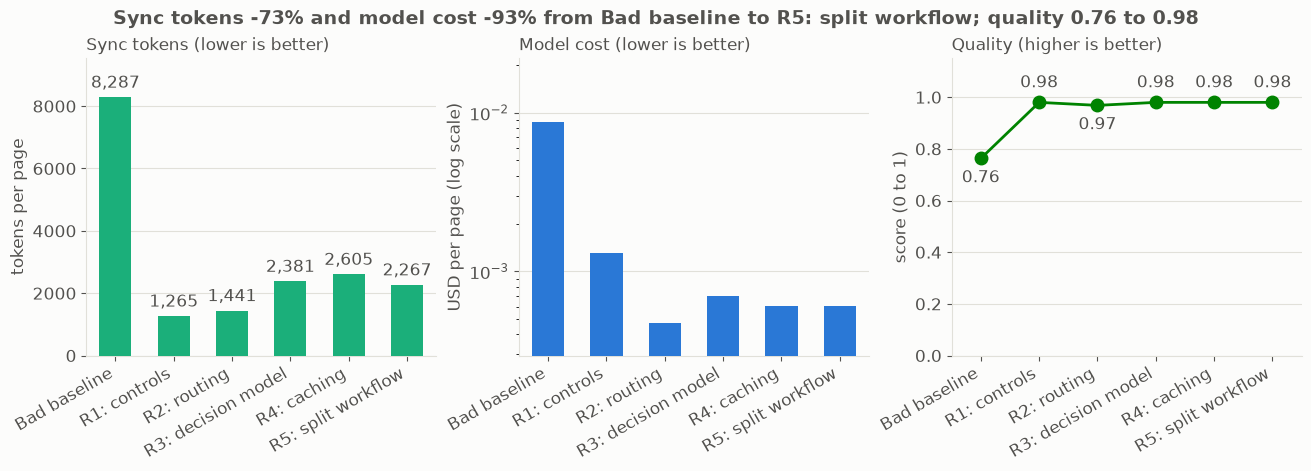

In [11]:
from doc_review_opt.reporting import plot_round_chart

display(plot_round_chart(summary))

**How to read it.** Left: model cost per page, with the change from the previous round. Right: median latency.

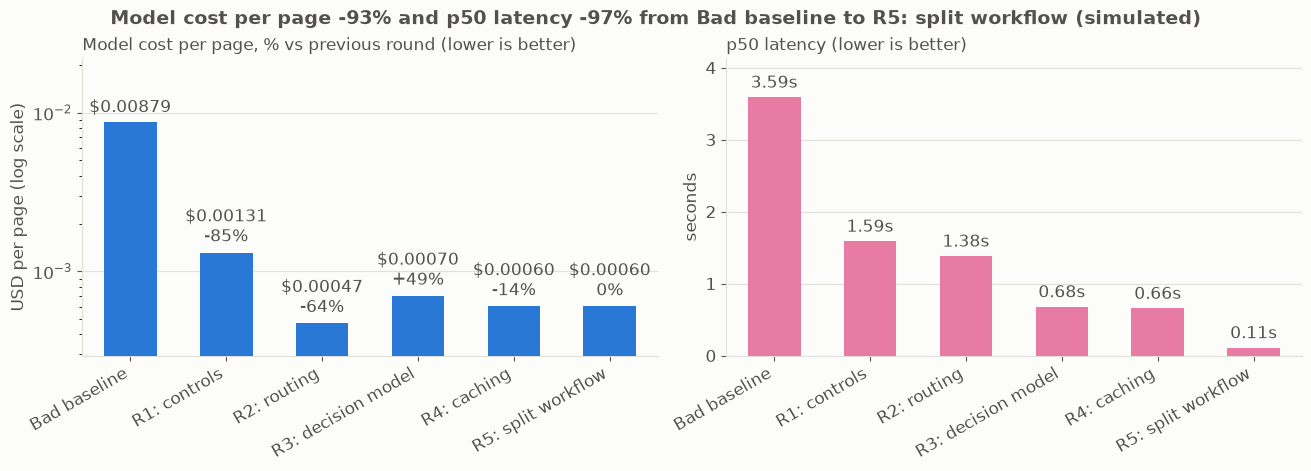

In [12]:
from doc_review_opt.reporting import plot_cost_latency

display(plot_cost_latency(summary))

### Where the money goes

**How to read it.** Orange is attorney time, blue is the model bill. The model bill is the sliver at the bottom.

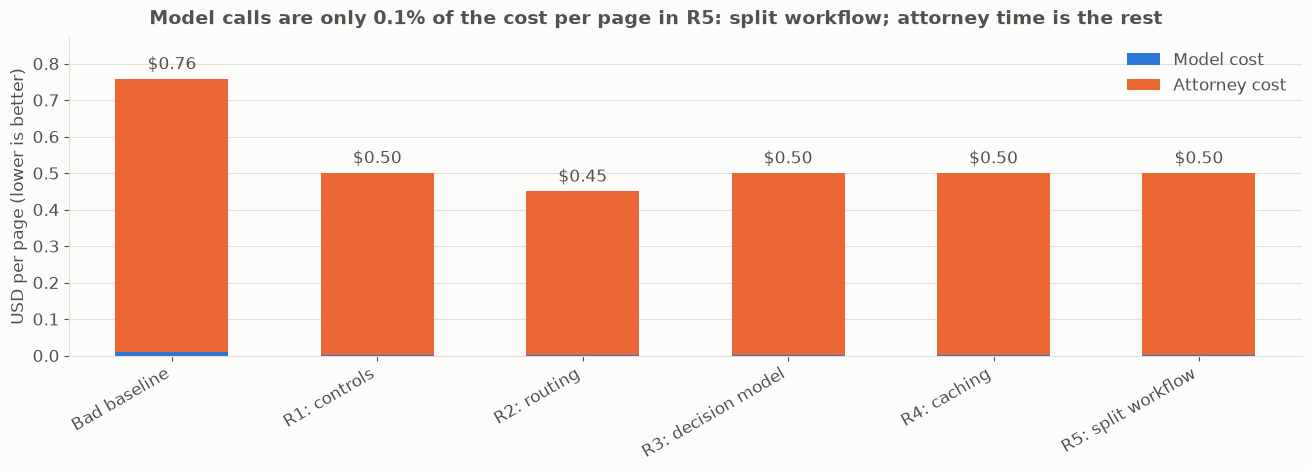

In [13]:
from doc_review_opt.reporting import plot_cost_split

display(plot_cost_split(summary))

## Round helpers

Every round has six beats: **symptom**, **lever**, **diff**, **re-measure**, **quality gate** and **tradeoff**. The helpers below keep them short.

In [14]:
from collections import Counter

from doc_review_opt.reporting import per_page_view, plot_progress
from doc_review_opt.simulation import variant_request_example
from doc_review_opt.traces import deterministic_guardrail_check
from doc_review_opt.variants import (
    BASELINE,
    CACHING,
    CONTROLS,
    ORIGINAL_WORDING_VARIANT,
    ROUTING,
    ROUTER_ONLY,
    SPLIT,
    VARIANT_LABELS,
)

GUARDRAIL_FLOOR = get_settings().quality.guardrail_pass_floor
PAGE_BY_ID = {page.doc_id: page for page in EVAL_SET}
SUMMARY_BY_VARIANT = full_summary.set_index("variant")
TRACES = {
    variant: [t for t in traces if t.variant == variant]
    for variant in VARIANT_ORDER + EXTRA_VARIANTS
}
PAGE_COLUMNS = ["route", "sync_tokens", "latency_s", "model_cost_usd", "quality_score"]
PAGE_FORMATS = {
    f"{column}_{side}": fmt
    for column, fmt in (
        ("sync_tokens", "{:,.0f}"),
        ("latency_s", "{:.2f}"),
        ("model_cost_usd", "${:.6f}"),
        ("quality_score", "{:.2f}"),
    )
    for side in ("before", "after")
} | {"cost_saved_usd": "${:+.6f}"}
SAMPLE_PAGE = next(page for page in EVAL_SET if page.labels.privileged)
LOW_PAGE = next(
    page for page in EVAL_SET if page.labels.risk == "low" and not page.labels.privileged
)
HIGH_PAGE = next(page for page in EVAL_SET if page.labels.risk == "high")


def guardrail_failures(variant):
    return Counter(
        code
        for trace in TRACES[variant]
        for code in deterministic_guardrail_check(PAGE_BY_ID[trace.doc_id], trace)
    )


def symptoms(variant):
    row = SUMMARY_BY_VARIANT.loc[variant]
    models = frame.loc[frame["variant"] == variant, "models_used"].value_counts()
    print(
        f"{VARIANT_LABELS[variant]}: {row['mean_tool_calls']:.1f} tool calls per page "
        f"({row['mean_extra_tool_calls']:.1f} unneeded), {row['mean_sync_tokens']:,.0f} sync tokens, "
        f"p50 {row['p50_latency_s']:.2f}s, model cost ${row['model_cost_per_page_usd']:.5f} per page"
    )
    print(f"  escalation rate {row['escalation_rate']:.0%}; privileged leaks {row['privileged_leaks']}, PII leaks {row['pii_leaks']}")
    print("  guardrail failures:", dict(guardrail_failures(variant)) or "none")
    print("  models used:", {name: int(count) for name, count in models.items()})


def request_facts(request):
    text = request.get("text", {})
    choice = request.get("tool_choice", "-")
    return {
        "model": request["model"],
        "reasoning": request.get("reasoning", {}).get("effort", "-"),
        "verbosity": text.get("verbosity", "-"),
        "structured_output": text.get("format", {}).get("name", "free text"),
        "max_output_tokens": request.get("max_output_tokens", "-"),
        "tool_choice": choice if isinstance(choice, str) else json.dumps(choice)[:40],
        "tools": ", ".join(sorted(tool["name"] for tool in request.get("tools", []))) or "-",
        "questions": ", ".join(q["name"] for q in request.get("questions", [])) or "-",
        "prompt_cache_key": request.get("prompt_cache_key", "-"),
        "instructions_chars": len(request.get("instructions", "")),
        "input_chars": len(json.dumps(request["input"])),
    }


def show_diff(before, after, page):
    old = request_facts(variant_request_example(before, page))
    new = request_facts(variant_request_example(after, page))
    rows = [{"setting": key, "before": old[key], "after": new[key]} for key in old if old[key] != new[key]]
    if rows:
        display(pd.DataFrame(rows).set_index("setting"))
    else:
        print("No request difference for this page.")


def short_json(value, limit=160):
    if isinstance(value, str):
        return value if len(value) <= limit else f"{value[:limit]}... [{len(value)} chars]"
    if isinstance(value, dict):
        return {key: short_json(item, limit) for key, item in value.items()}
    if isinstance(value, list):
        return [short_json(item, limit) for item in value]
    return value


def compare_rounds(previous, current, rows=8):
    before = per_page_view(frame, [previous], PAGE_COLUMNS).set_index("doc_id")
    after = per_page_view(frame, [current], PAGE_COLUMNS).set_index("doc_id")
    merged = before.drop(columns="variant_label").add_suffix("_before").join(
        after.drop(columns="variant_label").add_suffix("_after")
    )
    merged["cost_saved_usd"] = merged["model_cost_usd_before"] - merged["model_cost_usd_after"]
    changed = int((merged["route_before"] != merged["route_after"]).sum())
    print(f"Pages whose route changed: {changed} of {len(merged)}. Largest per-page cost changes:")
    display(merged.sort_values("cost_saved_usd", ascending=False).head(rows).style.format(PAGE_FORMATS))


def delta_row(variant):
    show(impact[summary["variant"] == variant])


def gate_result(current):
    row = SUMMARY_BY_VARIANT.loc[current]
    failed = sum(1 for trace in TRACES[current] if deterministic_guardrail_check(PAGE_BY_ID[trace.doc_id], trace))
    rate = 1 - failed / len(TRACES[current])
    hard_gates = row["privileged_leaks"] == 0 and row["pii_leaks"] == 0
    return rate, bool(hard_gates and rate >= GUARDRAIL_FLOOR)


def quality_gate(previous, current):
    row = SUMMARY_BY_VARIANT.loc[current]
    failures = guardrail_failures(current)
    rate, accepted = gate_result(current)
    print(f"Hard gates: privileged pages produced = {row['privileged_leaks']}, PII left in produced text = {row['pii_leaks']}")
    print(f"Guardrail pass rate: {rate:.0%} (floor {GUARDRAIL_FLOOR:.0%}); failures: {dict(failures) or 'none'}")
    print(f"Mean quality: {SUMMARY_BY_VARIANT.loc[previous, 'mean_quality']:.2f} -> {row['mean_quality']:.2f}")
    print(f"{VARIANT_LABELS[current]}: {'ACCEPTED' if accepted else 'REJECTED'}")

## Optional: live tool loop

The live helper in [live_api.py](../src/doc_review_opt/live_api.py) keeps reasoning and tool-call items between calls. After `max_tool_rounds` it sets `tool_choice="none"`. An incomplete or unparseable reply counts as a parse failure and the page goes to an attorney.

The example takes allowed tools from fixture labels; use evaluated logic in production. Live runs use the same graph and checks as the simulation, and every call is charged to the $1 budget.

In [15]:
from itertools import zip_longest

from doc_review_opt.exceptions import BudgetExceededError
from doc_review_opt.live_api import live_config_for_page, run_live_variant

by_route = {}
for page in EVAL_SET:
    by_route.setdefault(page.labels.expected_route, []).append(page)
LIVE_PAGES = [
    page for group in zip_longest(*by_route.values()) for page in group if page
][:LIVE_PAGE_LIMIT]

live_page = SAMPLE_PAGE
print(live_config_for_page(live_page, CONTROLS))

LiveReviewConfig(name='01_prompt_tool_context_controls', model='gpt-6.1-terra', instructions='Role: First-pass document reviewer on matter 24-CV-118.\n\nGoal: Give each page exactly one disposition with the fewest necessary tool calls\nwhile never producing a privileged page or leaving personal information in\nproduced text.\n\nTool rules:\n- Clearly responsive or clearly unrelated page, no personal data: no tools.\n- Responsive page with personal data: apply_redactions with the exact spans.\n- Attorney named in From or To, or relayed legal advice: lookup_custodian if a\n  name is unclear, then escalate_to_attorney with the reason only.\n- Attorney only in cc on business mail: lookup_custodian, then decide.\n- Possible copy of an earlier page: check_prior_production.\n- Damaged or illegible page: escalate_to_attorney.\n\nOutput rules:\n- Return the disposition JSON only: disposition, redact, reason.\n- Never quote page text in the reason.', tools=[{'type': 'function', 'name': 'lookup_c

In [16]:
if RUN_LIVE_API_CALLS:
    live_run = await run_live_variant(
        CONTROLS, [live_page], client=client, budget=budget, limit=1
    )
    live_trace = live_run.traces[0]
    display(
        pd.DataFrame(
            [
                {
                    "doc_id": live_trace.doc_id,
                    "route": live_trace.route,
                    "tool_calls": live_trace.tool_calls,
                    "latency_s": live_trace.latency_s,
                    "model_cost_usd": live_trace.model_cost_usd,
                    "input_tokens": live_trace.input_tokens,
                    "output_tokens": live_trace.output_tokens,
                    "trace_url": live_run.trace_url,
                }
            ]
        )
    )
    print(f"Running spend: ${budget.total_usd:.4f} of ${budget.limit_usd:.2f}")
else:
    print("Dry-run mode. Set OPENAI_API_KEY and RUN_LIVE_API_CALLS=true to run a live Responses API review page.")

Dry-run mode. Set OPENAI_API_KEY and RUN_LIVE_API_CALLS=true to run a live Responses API review page.


## Round 1: prompt, tool and context controls

```mermaid
flowchart LR
    A["All 5 tools<br/>verbose payloads"]:::before --> B["Only the needed tools<br/>slim payloads"]:::after
    C["Free-text answer"]:::before --> D["Strict JSON answer"]:::after
    classDef before fill:#e1e0d9,stroke:#52514e,stroke-width:1px,color:#1a1a18
    classDef after fill:#fcfcfb,stroke:#52514e,stroke-width:3px,color:#1a1a18
```

*Left is the baseline, right is the change: fewer tools and a strict answer.*

**Symptom.** The baseline calls every tool on every page, carries large payloads, and returns free text that sometimes cannot be parsed. It fails the personal-data gate.

In [17]:
symptoms(BASELINE)
quality_gate(BASELINE, BASELINE)

Bad baseline: 5.0 tool calls per page (4.2 unneeded), 8,287 sync tokens, p50 3.59s, model cost $0.00879 per page
  escalation rate 50%; privileged leaks 0, PII leaks 2
  guardrail failures: {'too_many_unnecessary_tools': 30, 'escalation_mismatch': 5, 'unnecessary_attorney_review': 5, 'unparseable_agent_output': 1, 'pii_in_produced_text': 2}
  models used: {'gpt-6.1-terra': 26, 'gpt-6.1-terra, gpt-6-luna': 4}
Hard gates: privileged pages produced = 0, PII left in produced text = 2
Guardrail pass rate: 0% (floor 95%); failures: {'too_many_unnecessary_tools': 30, 'escalation_mismatch': 5, 'unnecessary_attorney_review': 5, 'unparseable_agent_output': 1, 'pii_in_produced_text': 2}
Mean quality: 0.76 -> 0.76
Bad baseline: REJECTED


**Lever.** Same model, tighter rules:

- a controlled prompt with the fewest-tools and never-produce-privileged rules
- slim schemas and payloads
- `allowed_tools` per page type
- `verbosity="low"`, a strict `json_schema` answer and a `max_output_tokens` cap

Expected: far fewer tokens and no parse failures.

**Diff.** One privileged page, before and after.

In [18]:
show_diff(BASELINE, CONTROLS, SAMPLE_PAGE)

,before,after
setting,,
verbosity,high,low
structured_output,free text,review_disposition
max_output_tokens,1200,600
tool_choice,required,"{""type"": ""allowed_tools"", ""mode"": ""auto"""
instructions_chars,851,841
input_chars,529,416


In [19]:
from doc_review_opt.review_agent import BAD_BASELINE_PROMPT, CONTROLLED_PROMPT

print("--- baseline prompt ---")
print(BAD_BASELINE_PROMPT)
print("--- controlled prompt ---")
print(CONTROLLED_PROMPT)

--- baseline prompt ---
You are a comprehensive e-discovery review super-agent for a litigation team.

Always be extremely thorough. Before deciding, gather as much context as possible
from the protocol, the custodian directory, the prior production index, the
redaction system and the escalation queue. Prefer using tools even when the
answer may already be apparent. Explain your reasoning in detail so the
reviewing attorneys understand every step.

You are also responsible for drafting the privilege log entry, running QA on your
own call, and writing production tags before you give your disposition.

If there is any uncertainty, call more tools. If the protocol might be relevant,
retrieve every section. If a person might be an attorney, look them up. If a page
might be a copy, check prior production. If a page might contain personal
information, apply redactions.
--- controlled prompt ---
Role: First-pass document reviewer on matter 24-CV-118.

Goal: Give each page exactly one disposit

**Re-measure.** Same 30 pages, before and after.

In [20]:
compare_rounds(BASELINE, CONTROLS)
delta_row(CONTROLS)

Pages whose route changed: 7 of 30. Largest per-page cost changes:


,route_before,sync_tokens_before,latency_s_before,model_cost_usd_before,quality_score_before,route_after,sync_tokens_after,latency_s_after,model_cost_usd_after,quality_score_after,cost_saved_usd
doc_id,,,,,,,,,,,
ARC-000580,attorney_review,"10,529",3.95,$0.011057,0.91,attorney_review,"1,314",1.75,$0.001394,0.98,$+0.009663
ARC-000163,attorney_review,"8,886",4.11,$0.009257,0.36,produce,"1,233",1.45,$0.001305,0.98,$+0.007952
ARC-000497,attorney_review,"8,636",3.59,$0.009164,0.44,produce,"1,210",1.45,$0.001282,0.98,$+0.007882
ARC-000329,attorney_review,"8,660",3.59,$0.009188,0.44,produce,"1,237",1.45,$0.001309,0.98,$+0.007879
ARC-000245,withhold,"8,628",3.59,$0.009152,0.85,withhold,"1,202",1.44,$0.001274,0.98,$+0.007878
ARC-000259,withhold,"8,617",3.59,$0.009141,0.85,withhold,"1,191",1.44,$0.001263,0.98,$+0.007878
ARC-000212,withhold,"8,624",3.59,$0.009148,0.85,withhold,"1,199",1.44,$0.001271,0.98,$+0.007877
ARC-000333,withhold,"8,615",3.59,$0.009139,0.85,withhold,"1,190",1.44,$0.001262,0.98,$+0.007877


,variant_label,mean_quality,policy_compliance,escalation_rate,mean_tool_calls,mean_extra_tool_calls,mean_sync_tokens,mean_total_tokens,mean_cached_tokens,p50_latency_s,model_cost_per_page_usd,cost_per_page_usd,mean_sync_tokens_delta_vs_previous,mean_total_tokens_delta_vs_previous,p50_latency_s_delta_vs_previous,model_cost_per_page_usd_delta_vs_previous,cost_per_page_usd_delta_vs_previous,quality_delta_vs_previous
1,Round 1: controls,0.98,100%,33%,0.8,0.0,"1,265","1,265",0,1.59,$0.00131,$0.501,"-7,022","-7,022",-2.00,$-0.00748,$-0.257,+0.22


**Quality gate.** Accepted only if both hard gates are clear and the guardrail pass rate stays above the floor in `config.toml`.

In [21]:
quality_gate(BASELINE, CONTROLS)

Hard gates: privileged pages produced = 0, PII left in produced text = 0
Guardrail pass rate: 100% (floor 95%); failures: none
Mean quality: 0.76 -> 0.98
Round 1: controls: ACCEPTED


**Tradeoff.** The schema and allow-list are logic you now maintain, and the allow-list uses fixture labels. The strongest model still handles every page, which Round 2 addresses.

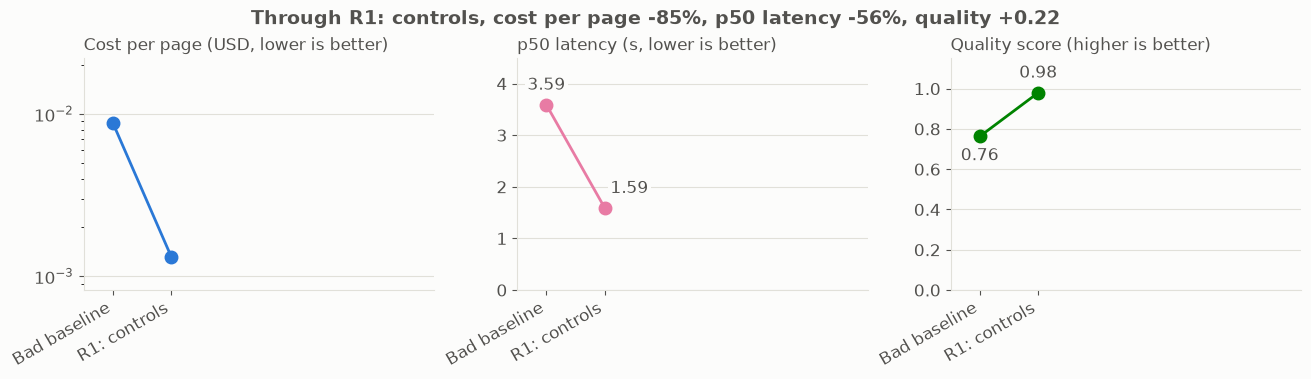

In [22]:
display(plot_progress(summary, upto_variant=CONTROLS))

## Round 2: model selection

```mermaid
flowchart LR
    A["Every page on terra"]:::before --> B["Triage on luna"]:::after
    B --> C["luna for routine pages"]:::after
    B --> D["terra for risky pages"]:::after
    classDef before fill:#e1e0d9,stroke:#52514e,stroke-width:1px,color:#1a1a18
    classDef after fill:#fcfcfb,stroke:#52514e,stroke-width:3px,color:#1a1a18
```

*Look at the split: cheap luna for routine pages, terra only for risky ones.*

**Symptom.** Round 1 spends `gpt-6.1-terra` tokens on obvious pages. Only privileged and borderline pages need the top tier.

In [23]:
symptoms(CONTROLS)

Round 1: controls: 0.8 tool calls per page (0.0 unneeded), 1,265 sync tokens, p50 1.59s, model cost $0.00131 per page
  escalation rate 33%; privileged leaks 0, PII leaks 0
  guardrail failures: none
  models used: {'gpt-6.1-terra': 25, 'gpt-6.1-terra, gpt-6-luna': 5}


**Lever.** A cheap `gpt-6-luna` triage step (`responsive`, `privileged`, `pii`, `needs_attorney`). Routine pages stay on `gpt-6-luna`; risky ones go to `gpt-6.1-terra`.

**Diff.** A low-risk page runs on the small model; a high-risk page stays on the strong one.

In [24]:
print("Low-risk page:")
show_diff(CONTROLS, ROUTING, LOW_PAGE)
print("High-risk page:")
show_diff(CONTROLS, ROUTING, HIGH_PAGE)

Low-risk page:


,before,after
setting,,
model,gpt-6.1-terra,gpt-6-luna


High-risk page:
No request difference for this page.


In [25]:
from doc_review_opt.live_api import triage_request

print(json.dumps(short_json(triage_request(LOW_PAGE), 220), indent=2))

{
  "model": "gpt-6-luna",
  "instructions": "Triage one page for e-discovery review. Return only the structured object: whether the page is responsive to the matter, whether it is privileged (an attorney is author or recipient, or it relays legal advice), whether i... [286 chars]",
  "input": "<page>\ndoc_id: ARC-000141\ncustodian: Dana Whitfield\nfrom: Finance Reporting\nto: -\ncc: -\n\nARCADIA FREIGHT -- Q3 2024 REVENUE SUMMARY (INTERNAL)\nRecognized revenue for the quarter ended 30 Sep 2024 was $48.2M, up 6% sequen... [414 chars]",
  "reasoning": {
    "effort": "none"
  },
  "text": {
    "format": {
      "type": "json_schema",
      "name": "page_triage",
      "strict": true,
      "schema": {
        "type": "object",
        "properties": {
          "responsive": {
            "type": "boolean"
          },
          "privileged": {
            "type": "boolean"
          },
          "pii": {
            "type": "boolean"
          },
          "needs_attorney": {
         

**Re-measure.**

In [26]:
compare_rounds(CONTROLS, ROUTING)
delta_row(ROUTING)

Pages whose route changed: 1 of 30. Largest per-page cost changes:


,route_before,sync_tokens_before,latency_s_before,model_cost_usd_before,quality_score_before,route_after,sync_tokens_after,latency_s_after,model_cost_usd_after,quality_score_after,cost_saved_usd
doc_id,,,,,,,,,,,
ARC-000572,withhold,"1,262",1.60,$0.001334,0.98,withhold,"1,450",1.39,$0.000169,0.98,$+0.001165
ARC-000377,redact,"1,475",2.11,$0.001377,0.98,redact,"1,668",1.90,$0.000224,0.98,$+0.001154
ARC-000413,produce,"1,241",1.59,$0.001313,0.98,produce,"1,426",1.38,$0.000167,0.98,$+0.001146
ARC-000352,redact,"1,448",2.10,$0.001362,0.98,redact,"1,631",1.89,$0.000216,0.98,$+0.001146
ARC-000329,produce,"1,237",1.45,$0.001309,0.98,produce,"1,434",1.24,$0.000167,0.98,$+0.001142
ARC-000306,produce,"1,234",1.59,$0.001306,0.98,produce,"1,413",1.38,$0.000165,0.98,$+0.001141
ARC-000390,redact,"1,430",2.10,$0.001352,0.98,redact,"1,605",1.89,$0.000213,0.98,$+0.001139
ARC-000463,redact,"1,414",2.09,$0.001345,0.98,redact,"1,589",1.88,$0.000206,0.98,$+0.001139


,variant_label,mean_quality,policy_compliance,escalation_rate,mean_tool_calls,mean_extra_tool_calls,mean_sync_tokens,mean_total_tokens,mean_cached_tokens,p50_latency_s,model_cost_per_page_usd,cost_per_page_usd,mean_sync_tokens_delta_vs_previous,mean_total_tokens_delta_vs_previous,p50_latency_s_delta_vs_previous,model_cost_per_page_usd_delta_vs_previous,cost_per_page_usd_delta_vs_previous,quality_delta_vs_previous
2,Round 2: routing,0.97,97%,30%,0.8,0.0,"1,441","1,441",0,1.38,$0.00047,$0.450,+176,+176,-0.21,$-0.00084,$-0.051,-0.01


**Quality gate.** Check the cheap model's mistakes in the guardrail failures, not only the hard gates.

In [27]:
quality_gate(CONTROLS, ROUTING)

Hard gates: privileged pages produced = 0, PII left in produced text = 0
Guardrail pass rate: 97% (floor 95%); failures: {'escalation_mismatch': 1}
Mean quality: 0.98 -> 0.97
Round 2: routing: ACCEPTED


**Tradeoff.** Triage adds tokens to every page, and a wrong triage becomes a wrong escalation. Triage is also an LLM doing classification, which opens the door to Round 3.

**Live (2026-11-18, 6 pages).** Round 2 was slower than Round 1 (p50 4.00s against 2.96s) and misrouted one page (quality 0.95). Model cost per page did fall ($0.00039 against $0.00112). The simulated latency gain is a formula, not a measurement.

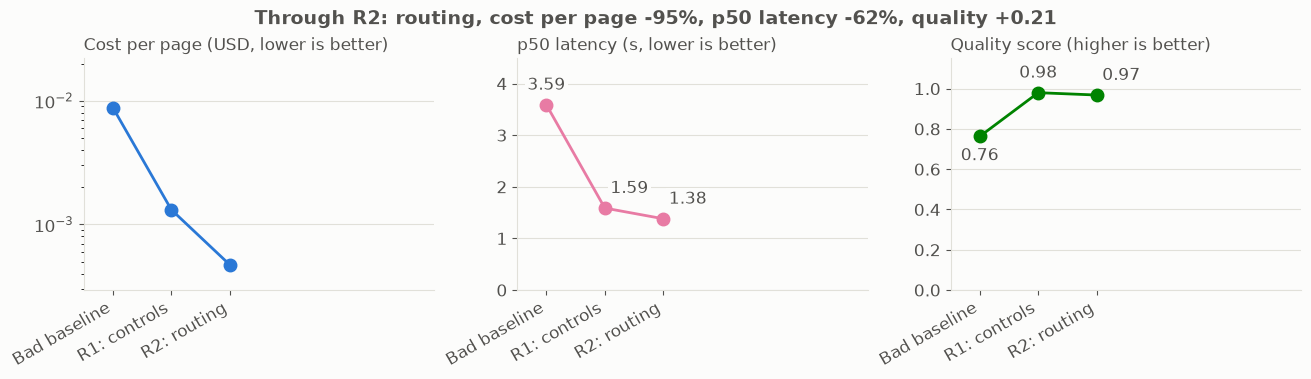

In [28]:
display(plot_progress(summary, upto_variant=ROUTING))

## Round 3: replace the LLM with a decision model

```mermaid
flowchart LR
    A["An LLM classifies<br/>every page"]:::before --> B["Decisions call"]:::after
    B --> C["Code router"]:::after
    C --> D["terra second opinion<br/>ambiguous band only"]:::after
    classDef before fill:#e1e0d9,stroke:#52514e,stroke-width:1px,color:#1a1a18
    classDef after fill:#fcfcfb,stroke:#52514e,stroke-width:3px,color:#1a1a18
```

*Look at who decides: a typed Decisions call and plain code, with an LLM only on the ambiguous band.*

**Symptom.** The agent still uses an LLM to classify: responsive, privileged, personal data. Its confidence is not a probability and the thresholds are buried in a prompt. This is a typed decision, which the Decisions API answers directly.

In [29]:
symptoms(ROUTING)

Round 2: routing: 0.8 tool calls per page (0.0 unneeded), 1,441 sync tokens, p50 1.38s, model cost $0.00047 per page
  escalation rate 30%; privileged leaks 0, PII leaks 0
  guardrail failures: {'escalation_mismatch': 1}
  models used: {'gpt-6-luna, gpt-6-luna': 22, 'gpt-6-luna, gpt-6.1-terra': 8}


**Lever.** One Decisions call on `gpt-6-luna` asks three typed questions: a `score` for responsiveness (three levels) and `predicate`s for privileged and contains-personal-data. **Plain code** routes the answers:

- privilege probability above the threshold goes to an attorney (privilege beats personal data)
- responsiveness below the not-responsive threshold is withheld
- an ambiguous score, or a responsive score with low confidence, goes to an attorney
- otherwise personal data above its threshold is redacted, else produced

An LLM stays only where Decisions cannot help: redaction text (`gpt-6-luna`) and a `gpt-6.1-terra` second opinion on the ambiguous band. A prior-production check in code skips the model call entirely. Thresholds are calibrated on the calibration split, never the holdout.

**Diff.** The Round 2 request next to the Decisions request. The protocol goes first in `input` so it can be cached; the policy lives in each question.

In [30]:
from doc_review_opt.decisions import (
    DECISIONS_MODEL,
    DEFAULT_POLICY,
    build_decisions_request,
    decide,
)
from doc_review_opt.review_agent import PROTOCOL

show_diff(ROUTING, DECISION_MODEL, SAMPLE_PAGE)
print(json.dumps(short_json(build_decisions_request(SAMPLE_PAGE, PROTOCOL), 200), indent=2))

,before,after
setting,,
model,gpt-6.1-terra,gpt-6-luna
reasoning,none,-
verbosity,low,-
structured_output,review_disposition,free text
max_output_tokens,600,-
tool_choice,"{""type"": ""allowed_tools"", ""mode"": ""auto""",-
tools,"apply_redactions, check_prior_production, escalate_to_attorney, lookup_custodian, lookup_protocol",-
questions,-,"responsive, privileged, contains_pii"
instructions_chars,841,0


{
  "model": "gpt-6-luna",
  "questions": [
    {
      "type": "score",
      "name": "responsive",
      "instructions": "How relevant is this page to the matter described in the review protocol?",
      "levels": [
        {
          "label": "not_responsive",
          "description": "Not responsive: unrelated to the matter."
        },
        {
          "label": "possibly_responsive",
          "description": "Possibly responsive: touches on the matter indirectly."
        },
        {
          "label": "responsive",
          "description": "Responsive: directly concerns the matter."
        }
      ]
    },
    {
      "type": "predicate",
      "name": "privileged",
      "instructions": "Was this page written by or to a lawyer, or does it convey a lawyer's legal advice? Answer no for ordinary business, finance, or accounting discussion, even when the subject is litigation-sensitive.\n\n... [660 chars]"
    },
    {
      "type": "predicate",
      "name": "contains_pii",
 

The typed answer for the same page (simulated): a `score` with level probabilities and a confidence, and one probability per predicate.

In [31]:
from doc_review_opt.simulation import SimulatedTypedClassifier

sample = await SimulatedTypedClassifier("decisions").classify(SAMPLE_PAGE, PROTOCOL)
print(sample.model_dump_json(indent=2))

{
  "engine": "decisions",
  "model": "gpt-6-luna",
  "answers": {
    "responsive": {
      "type": "score",
      "name": "responsive",
      "score": 1.859381964075122,
      "confidence": 0.6259694102467477,
      "probabilities": [
        0.032450315982664166,
        0.07571740395954969,
        0.8918322800577861
      ]
    },
    "privileged": {
      "type": "predicate",
      "name": "privileged",
      "probability": 0.8996675994477706
    },
    "contains_pii": {
      "type": "predicate",
      "name": "contains_pii",
      "probability": 0.04167307115990906
    }
  },
  "agent_disposition": null,
  "agent_redact": null,
  "usage": {
    "input": 1676,
    "cached": 0,
    "cache_write": 0,
    "output": 36,
    "reasoning": 0
  },
  "latency_s": 0.1319,
  "cost_usd": 0.00016760000000000004,
  "error": null,
  "models": [
    "gpt-6-luna"
  ],
  "tools": [],
  "routing_tokens": 0,
  "parse_failed": false
}


In [32]:
if RUN_LIVE_API_CALLS:
    from doc_review_opt.decisions import DecisionsClassifier
    from doc_review_opt.live_api import BudgetedClassifier

    budget.check()
    live_sample = await BudgetedClassifier(DecisionsClassifier(client), budget).classify(
        SAMPLE_PAGE, PROTOCOL
    )
    print(live_sample.model_dump_json(indent=2))
    print(f"Running spend: ${budget.total_usd:.4f} of ${budget.limit_usd:.2f}")
else:
    print("Dry-run mode. Set OPENAI_API_KEY and RUN_LIVE_API_CALLS=true to send this page to the real Decisions API.")

Dry-run mode. Set OPENAI_API_KEY and RUN_LIVE_API_CALLS=true to send this page to the real Decisions API.


The router is ordinary code, so reading it is the audit. Each outcome has a named reason, a refusal or error can only escalate, and each threshold is one tunable number.

In [33]:
print(inspect.getsource(decide))
print(inspect.getsource(type(DEFAULT_POLICY)))

def decide(
    result: ClassifierResult, policy: RoutingPolicy = DEFAULT_POLICY
) -> RouteDecision:
    if result.error is not None:
        return RouteDecision("attorney_review", "classifier_error")
    if any(isinstance(a, RefusalAnswer) for a in result.answers.values()):
        return RouteDecision("attorney_review", "missing_or_refused_answer")
    if result.agent_disposition is not None:
        return _route_agent(result.agent_disposition, result, policy)
    typed = _typed_answers(result)
    if typed is None:
        return RouteDecision("attorney_review", "missing_or_refused_answer")
    responsive, privileged, pii = typed
    if privileged.probability > policy.privilege_escalation:
        return RouteDecision("attorney_review", "privilege_above_threshold")
    if responsive.score < policy.not_responsive:
        return RouteDecision("withhold", "not_responsive")
    if responsive.score < policy.responsive:
        return RouteDecision("attorney_review", "ambiguous_respons

**Re-measure.** Round 2 against full Round 3, then Decisions alone against Decisions plus the second opinion.

In [34]:
compare_rounds(ROUTING, DECISION_MODEL)
delta_row(DECISION_MODEL)
show(
    full_summary[full_summary["variant"].isin([ROUTER_ONLY, DECISION_MODEL])][
        [
            "variant_label",
            "mean_quality",
            "route_accuracy",
            "escalation_rate",
            "p50_latency_s",
            "model_cost_per_page_usd",
            "cost_per_page_usd",
        ]
    ]
)

Pages whose route changed: 1 of 30. Largest per-page cost changes:


,route_before,sync_tokens_before,latency_s_before,model_cost_usd_before,quality_score_before,route_after,sync_tokens_after,latency_s_after,model_cost_usd_after,quality_score_after,cost_saved_usd
doc_id,,,,,,,,,,,
ARC-000580,attorney_review,"1,530",1.91,$0.001342,0.98,attorney_review,0,0.00,$0.000000,0.98,$+0.001342
ARC-000401,attorney_review,"1,495",1.90,$0.001315,0.98,attorney_review,"2,141",0.68,$0.000246,0.98,$+0.001068
ARC-000472,attorney_review,"1,473",1.90,$0.001302,0.98,attorney_review,"2,121",0.68,$0.000245,0.98,$+0.001057
ARC-000518,attorney_review,"1,453",1.90,$0.001291,0.98,attorney_review,"2,101",0.68,$0.000243,0.98,$+0.001048
ARC-000284,attorney_review,"1,429",1.89,$0.001278,0.98,attorney_review,"2,075",0.67,$0.000240,0.98,$+0.001038
ARC-000441,attorney_review,"1,440",1.75,$0.001277,0.98,attorney_review,"2,103",0.68,$0.000243,0.98,$+0.001034
ARC-000299,attorney_review,"1,420",1.89,$0.001273,0.98,attorney_review,"2,067",0.67,$0.000239,0.98,$+0.001034
ARC-000572,withhold,"1,450",1.39,$0.000169,0.98,withhold,0,0.00,$0.000000,0.98,$+0.000169


,variant_label,mean_quality,policy_compliance,escalation_rate,mean_tool_calls,mean_extra_tool_calls,mean_sync_tokens,mean_total_tokens,mean_cached_tokens,p50_latency_s,model_cost_per_page_usd,cost_per_page_usd,mean_sync_tokens_delta_vs_previous,mean_total_tokens_delta_vs_previous,p50_latency_s_delta_vs_previous,model_cost_per_page_usd_delta_vs_previous,cost_per_page_usd_delta_vs_previous,quality_delta_vs_previous
3,Round 3: decision model,0.98,100%,33%,0.1,0.0,"2,381","2,381",0,0.68,$0.00070,$0.501,+940,+940,-0.70,$+0.00023,$+0.050,+0.01


,variant_label,mean_quality,route_accuracy,escalation_rate,p50_latency_s,model_cost_per_page_usd,cost_per_page_usd
3,Round 3: decision model,0.98,100%,33%,0.68,$0.00070,$0.501
6,Decisions + code router,0.93,87%,47%,0.67,$0.00023,$0.700


**Quality gate.** Decisions alone is fast and cheap, but its mistakes show in the guardrails. That is why the second opinion exists.

In [35]:
quality_gate(ROUTING, DECISION_MODEL)
print()
quality_gate(ROUTING, ROUTER_ONLY)

Hard gates: privileged pages produced = 0, PII left in produced text = 0
Guardrail pass rate: 100% (floor 95%); failures: none
Mean quality: 0.97 -> 0.98
Round 3: decision model: ACCEPTED

Hard gates: privileged pages produced = 0, PII left in produced text = 0
Guardrail pass rate: 87% (floor 95%); failures: {'escalation_mismatch': 4, 'unnecessary_attorney_review': 4}
Mean quality: 0.97 -> 0.93
Decisions + code router: REJECTED


### Lever: put the protocol in the question

**The policy lives in the question.** The protocol says an attorney merely copied on business mail does not make a page privileged. The first `privileged` question only said "a named attorney is the author or recipient". In the simulation that over-flags cc'd mail. The fix is in the question text, not the thresholds. The two texts side by side:

In [36]:
import difflib

from doc_review_opt.decisions import (
    ORIGINAL_PRIVILEGE_INSTRUCTIONS,
    PROTOCOL_PRIVILEGE_INSTRUCTIONS,
)

print("\n".join(difflib.unified_diff(
    ORIGINAL_PRIVILEGE_INSTRUCTIONS.splitlines(),
    PROTOCOL_PRIVILEGE_INSTRUCTIONS.splitlines(),
    fromfile="original wording",
    tofile="protocol wording",
    lineterm="",
)))

--- original wording
+++ protocol wording
@@ -2,3 +2,4 @@
 
 True when: a named attorney is the author or recipient, or the text relays legal advice or litigation strategy.
 False when: business, finance, operations, or accounting content with no attorney involved -- including discussion of restatements, audits, or regulatory exposure.
+An attorney who only appears on cc of ordinary business, finance or operations mail does not make the page privileged unless the text itself relays legal advice or litigation strategy.


**Ablation.** `03b` is Round 3 with the original wording; `03_decision_model` uses the protocol wording. Read the verdicts from the table.

**Simulation assumption.** The dry-run privileged probability for cc'd mail under the protocol wording is a `config.toml` value, not a measurement.

**The live run refuted it (2026-11-18).** The real API scored ARC-000306 at 0.02 (original wording) and 0.00 (protocol wording), and ARC-000413 at 0.00 with both. The simulated over-escalation of about 0.3 did not reproduce, so `03b` is a simulation-only illustration. The protocol wording stays because it is free and matches the protocol.

In [37]:
import pandas as pd

ablation_rows = []
for variant in (ORIGINAL_WORDING_VARIANT, DECISION_MODEL):
    rate, accepted = gate_result(variant)
    row = SUMMARY_BY_VARIANT.loc[variant]
    ablation_rows.append(
        {
            "variant": VARIANT_LABELS[variant],
            "escalation_rate": row["escalation_rate"],
            "unnecessary_attorney_reviews": sum(t.unnecessary_escalation for t in TRACES[variant]),
            "privileged_leaks": row["privileged_leaks"],
            "guardrail_pass": rate,
            "quality_gate": "ACCEPTED" if accepted else "REJECTED",
        }
    )
display(
    pd.DataFrame(ablation_rows).style.format(
        {"escalation_rate": "{:.0%}", "guardrail_pass": "{:.0%}"}
    )
)
print()
quality_gate(ROUTING, ORIGINAL_WORDING_VARIANT)

,variant,escalation_rate,unnecessary_attorney_reviews,privileged_leaks,guardrail_pass,quality_gate
0,"Round 3, original wording",40%,2,0,93%,REJECTED
1,Round 3: decision model,33%,0,0,100%,ACCEPTED



Hard gates: privileged pages produced = 0, PII left in produced text = 0
Guardrail pass rate: 93% (floor 95%); failures: {'escalation_mismatch': 2, 'unnecessary_attorney_review': 2}
Mean quality: 0.97 -> 0.95
Round 3, original wording: REJECTED


In [38]:
from doc_review_opt.decisions import ORIGINAL_WORDING
from doc_review_opt.simulation import simulated_answers

cc_pages = [page for page in EVAL_SET if page.cc and not page.labels.privileged]
if RUN_LIVE_API_CALLS:
    from doc_review_opt.decisions import DecisionsClassifier
    from doc_review_opt.live_api import BudgetedClassifier

    budget.check(reserve_usd=2 * len(cc_pages) * LIVE.per_page_ceiling_usd)
    for page in cc_pages:
        for label, wording in (("original", ORIGINAL_WORDING), ("protocol", "protocol")):
            live = await BudgetedClassifier(
                DecisionsClassifier(client, wording=wording), budget
            ).classify(page, PROTOCOL)
            answer = live.answers.get("privileged")
            print(f"LIVE {page.doc_id} {label:>8} wording: privileged probability = {getattr(answer, 'probability', None)}")
    print(f"Running spend: ${budget.total_usd:.4f} of ${budget.limit_usd:.2f}")
else:
    for page in cc_pages:
        for label, wording in (("original", ORIGINAL_WORDING), ("protocol", "protocol")):
            probability = simulated_answers(page, "decisions", wording)["privileged"].probability
            print(f"SIMULATION ASSUMPTION {page.doc_id} {label:>8} wording: privileged probability = {probability:.3f}")
    print("Dry-run mode: set RUN_LIVE_API_CALLS=true to measure the real Decisions probabilities on these pages.")

SIMULATION ASSUMPTION ARC-000306 original wording: privileged probability = 0.276
SIMULATION ASSUMPTION ARC-000306 protocol wording: privileged probability = 0.056
SIMULATION ASSUMPTION ARC-000413 original wording: privileged probability = 0.325
SIMULATION ASSUMPTION ARC-000413 protocol wording: privileged probability = 0.105
Dry-run mode: set RUN_LIVE_API_CALLS=true to measure the real Decisions probabilities on these pages.


The escalation came from one question's wording, so in the simulation the fix is one sentence, already in the protocol. Live, the lever was not needed (see "What the live run showed").

### Uncalibrated vs calibrated thresholds

The default privilege threshold of 0.2 was tuned for another engine. `calibrate_policy` searches a small grid (privilege, PII, responsiveness confidence) on the **calibration split only**. It picks the cheapest policy with zero hard-gate leaks, breaking ties by distance from the default. The holdout then shows whether it generalizes.

Under the protocol wording, cc'd business mail already scores below 0.2 for privilege, so a higher bar has little to gain. The printout shows the picked threshold next to the default. In production, recalibrate whenever the engine, prompt or matter changes.

In [39]:
from doc_review_opt.review_agent import CALIBRATION, HOLDOUT
from doc_review_opt.tradeoffs import (
    calibrate_policy,
    engine_comparison_table,
    policy_report,
    simulate_engine_comparison,
)

engine_runs_default = await simulate_engine_comparison()
engine_runs_calibrated = await simulate_engine_comparison(policy=CALIBRATED_POLICY)
decisions_results = {
    result.doc_id: result.classification
    for result in engine_runs_default["decisions"].outcome.results
}
picked = calibrate_policy(decisions_results, CALIBRATION)
print("Picked on the calibration split:", picked)
print(
    "Privilege escalation threshold: default",
    DEFAULT_POLICY.privilege_escalation,
    "-> calibrated",
    picked.privilege_escalation,
)
print("Matches the policy stored in config.toml:", picked == CALIBRATED_POLICY)
policy_table = policy_report(
    decisions_results,
    {"calibration": CALIBRATION, "holdout": HOLDOUT},
    {"default": DEFAULT_POLICY, "calibrated": CALIBRATED_POLICY},
)
display(
    policy_table.style.format(
        {
            "escalation_rate": "{:.0%}",
            "mean_quality": "{:.2f}",
            "blended_cost_per_page_usd": "${:.3f}",
        }
    )
)

Picked on the calibration split: RoutingPolicy(privilege_escalation=0.2, pii_redaction=0.5, not_responsive=0.5, responsive=1.5, responsive_confidence=0.6)
Privilege escalation threshold: default 0.2 -> calibrated 0.2
Matches the policy stored in config.toml: True


,policy,split,escalation_rate,privileged_leaks,pii_leaks,mean_quality,blended_cost_per_page_usd
0,default,calibration,81%,0,0,0.77,$1.219
1,calibrated,calibration,44%,0,0,0.93,$0.656
2,default,holdout,86%,0,0,0.78,$1.286
3,calibrated,holdout,57%,0,0,0.89,$0.857


**How to read it.** Each pair is one split. Yellow is the default thresholds, green the calibrated ones.

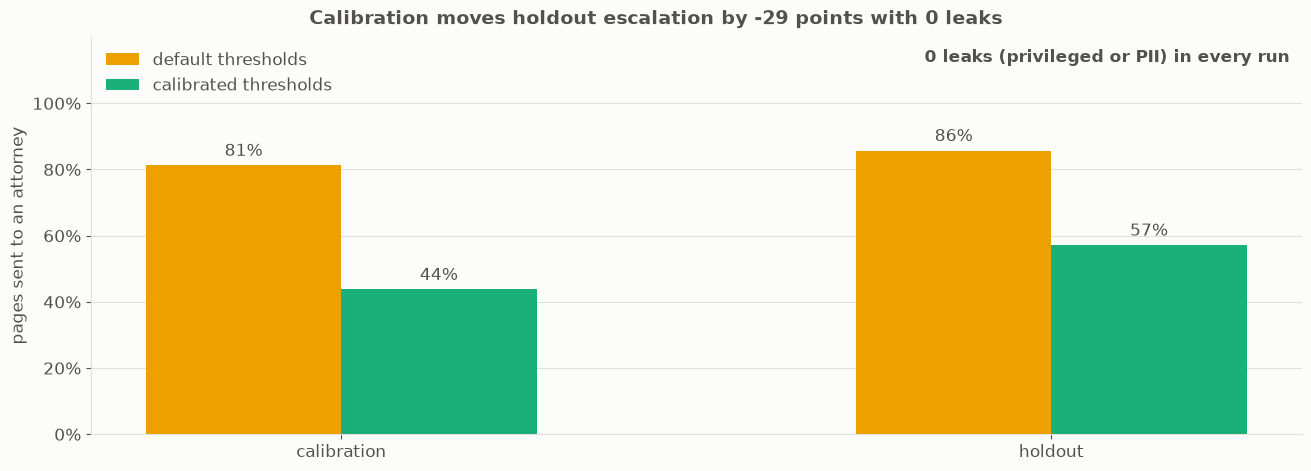

In [40]:
from doc_review_opt.tradeoffs import plot_calibration

display(plot_calibration(policy_table))

The calibrated policy keeps the privilege threshold unchanged, since cc'd pages already score below 0.2. The simulated original-wording ablation (Round 3b) is where those pages score higher. The grid searches thresholds only, so the quality gate still decides and rejected rounds stay rejected.

### Three lessons

**1. A score is an expected value, not a class.** A `score` question returns the probability-weighted average of its levels. A page split across two levels lands between them, say 1.4, and goes to the ambiguous band. Do not read 1.4 as "level 1".

In [41]:
spread_page = next(
    page
    for page in EVAL_SET
    if page.labels.responsive_level == 2
    and decisions_results[page.doc_id].answers["responsive"].score < 1.5
)
answer = decisions_results[spread_page.doc_id].answers["responsive"]
print(f"{spread_page.doc_id}: labelled responsive level {spread_page.labels.responsive_level}")
print("level probabilities:", [round(p, 2) for p in answer.probabilities])
print("expected value     :", round(sum(i * p for i, p in enumerate(answer.probabilities)), 2))
print("reported score     :", round(answer.score, 2))

ARC-000306: labelled responsive level 2
level probabilities: [0.14, 0.34, 0.52]
expected value     : 1.37
reported score     : 1.37


**2. Confidence is not correctness.** It measures how sharp the distribution is, not whether the label is right. In the router it only gates "responsive" to "produce"; it never gates privilege, personal data or the not-responsive withhold. The table splits each engine's confidence by whether its rounded score matched the label.

In [42]:
confidence_rows = [
    {
        "engine": name,
        "correct_level": round(result.classification.answers["responsive"].score)
        == PAGE_BY_ID[result.doc_id].labels.responsive_level,
        "confidence": result.classification.answers["responsive"].confidence,
    }
    for name in ("decisions", "llm-luna", "llm-terra")
    for result in engine_runs_default[name].outcome.results
]
confidence_table = pd.DataFrame(confidence_rows)
display(
    confidence_table.groupby(["engine", "correct_level"])["confidence"]
    .agg(["count", "mean", "max"])
    .style.format({"mean": "{:.2f}", "max": "{:.2f}"})
)

**3. Confidence does not port across engines.** The same threshold means different things per engine. Below, one router and one set of thresholds are applied to Decisions and to two LLMs asked for the same probabilities. Escalation and accuracy move a lot, and recalibrating changes them again.

In [43]:
ENGINE_FORMATS = {
    "accuracy_vs_labels": "{:.0%}",
    "agreement_vs_decisions": "{:.0%}",
    "cost_per_page_usd": "${:.5f}",
    "cost_per_100k_pages_usd": "${:,.0f}",
    "p50_latency_s": "{:.2f}",
    "mean_sync_tokens": "{:,.0f}",
    "escalation_rate": "{:.0%}",
}
print("Default thresholds:")
display(engine_comparison_table(engine_runs_default).drop(columns="label").style.format(ENGINE_FORMATS))
print("Calibrated thresholds:")
display(engine_comparison_table(engine_runs_calibrated).drop(columns="label").style.format(ENGINE_FORMATS))

Default thresholds:


,engine,accuracy_vs_labels,agreement_vs_decisions,cost_per_page_usd,cost_per_100k_pages_usd,p50_latency_s,mean_sync_tokens,escalation_rate,privileged_leaks,pii_leaks
0,decisions,50%,100%,$0.00018,$18,0.13,"1,746",83%,0,0
1,llm-luna,80%,70%,$0.00021,$21,0.81,"1,806",53%,0,1
2,llm-terra,97%,50%,$0.00203,$203,1.18,"1,812",33%,0,0
3,agent,100%,50%,$0.00131,$131,1.59,"1,265",33%,0,0


Calibrated thresholds:


,engine,accuracy_vs_labels,agreement_vs_decisions,cost_per_page_usd,cost_per_100k_pages_usd,p50_latency_s,mean_sync_tokens,escalation_rate,privileged_leaks,pii_leaks
0,decisions,83%,100%,$0.00018,$18,0.13,"1,746",50%,0,0
1,llm-luna,80%,97%,$0.00021,$21,0.81,"1,806",50%,0,1
2,llm-terra,97%,83%,$0.00203,$203,1.18,"1,812",33%,0,0
3,agent,100%,83%,$0.00131,$131,1.59,"1,265",33%,0,0


### What Decisions can't do

| Need | Why a decision model does not cover it | What to use |
|---|---|---|
| Generate text (redacted page, privilege-log entry) | Answers are typed numbers and choices only | `gpt-6-luna` Responses call, or a Batch job |
| Extract spans into your own schema | There is no free-form output | An LLM with a strict `json_schema` |
| Call tools or look things up | There is no tool loop | The code around the call, or an agent step |
| Explain itself for a privilege log | It returns probabilities, not reasons | An LLM, run after the decision and only where a reason is required |
| Choose a stronger model | Only `gpt-6-luna` is supported | `gpt-6.1-terra` as a second opinion on the ambiguous band |
| Always answer | Any answer can come back as a refusal | Fail safe: treat a refusal as "ask an attorney" |

A refusal never produces or withholds a page; it escalates.

In [44]:
from doc_review_opt.models import ClassifierResult, RefusalAnswer

refused = ClassifierResult(
    engine="decisions",
    model=DECISIONS_MODEL,
    answers={"privileged": RefusalAnswer(name="privileged")},
)
print(decide(refused))

RouteDecision(route='attorney_review', reason='missing_or_refused_answer')


**Tradeoff.** A decision model is far cheaper than `gpt-6.1-terra` and several times faster than either LLM, and its numbers can be calibrated and audited. It is not always cheaper than the smallest LLM.

**Live (2026-11-18, 6 pages).** Decisions was about 6x faster than `gpt-6-luna` as an LLM classifier but about 1.7x more expensive per page. Against `gpt-6.1-terra` it was 4 to 6x cheaper and 6 to 8x faster.

You also own the thresholds, cannot ask it to explain itself, and its edge mistakes are why a second opinion sits before the attorney. Compare model cost, escalation rate and blended cost per page with Round 2: an extra attorney review costs far more than the model calls it replaces.

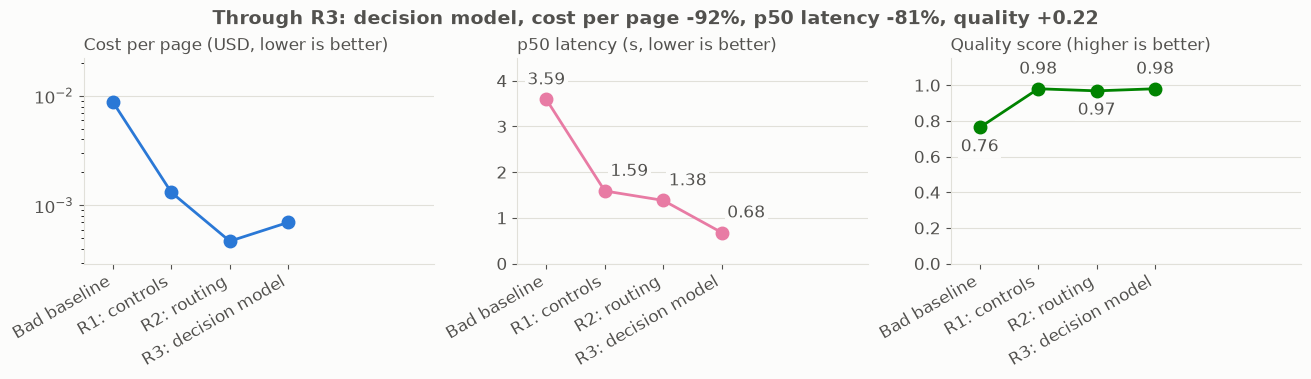

In [45]:
display(plot_progress(summary, upto_variant=DECISION_MODEL))

## Round 4: prompt caching

```mermaid
flowchart LR
    A["Page mixed into the prompt<br/>nothing cached"]:::before --> B["Stable protocol prefix<br/>cached"]:::after
    B --> C["Page<br/>changes every call"]:::after
    classDef before fill:#e1e0d9,stroke:#52514e,stroke-width:1px,color:#1a1a18
    classDef after fill:#fcfcfb,stroke:#52514e,stroke-width:3px,color:#1a1a18
```

*Look at the order: the part that never changes comes first, so it can be cached.*

**Symptom.** Every Decisions call resends the same protocol before the page, billed as ordinary input each time.

In [46]:
symptoms(DECISION_MODEL)

Round 3: decision model: 0.1 tool calls per page (0.0 unneeded), 2,381 sync tokens, p50 0.68s, model cost $0.00070 per page
  escalation rate 33%; privileged leaks 0, PII leaks 0
  guardrail failures: none
  models used: {'gpt-6-luna': 21, 'gpt-6-luna, gpt-6.1-terra': 7, 'code': 2}


**Lever.** Protocol first in the Decisions `input`, page last, and a `prompt_cache_key` per matter.

- Only an `input` prefix of at least 1,024 tokens is cached.
- **Questions are never cached**, so keep them short.
- A cache write costs 1.25x the input price, so the prefix must be reused enough.

**Live vs simulated.** Live caching here is Decisions-only. Round 3 may already cache an implicit prefix, so live Round 3 against Round 4 does not isolate this lever. Redaction-prefix caching is simulation-only.

**Diff.**

In [47]:
from doc_review_opt.decisions import QUESTIONS, protocol_block
from doc_review_opt.live_api import CACHE_KEY
from doc_review_opt.pricing import CACHE_MIN_TOKENS

print(f"Stable protocol prefix: about {approx_tokens(protocol_block(PROTOCOL)):,} tokens (minimum for caching: {CACHE_MIN_TOKENS:,})")
print(f"Questions re-billed on every call (never cached): about {approx_tokens(QUESTIONS):,} tokens")
print("prompt_cache_key:", CACHE_KEY)
show_diff(DECISION_MODEL, CACHING, SAMPLE_PAGE)

Stable protocol prefix: about 1,250 tokens (minimum for caching: 1,024)
Questions re-billed on every call (never cached): about 333 tokens
prompt_cache_key: matter-24-CV-118 (Hollis v. Arcadia Freight)


,before,after
setting,,
prompt_cache_key,-,matter-24-CV-118 (Hollis v. Arcadia Freight)


**Re-measure.**

In [48]:
compare_rounds(DECISION_MODEL, CACHING)
delta_row(CACHING)
display(
    frame[frame["variant"] == CACHING][
        ["doc_id", "input_tokens", "cached_tokens", "cache_write_tokens", "model_cost_usd"]
    ]
    .head(6)
    .style.format({"model_cost_usd": "${:.6f}"})
)

Pages whose route changed: 0 of 30. Largest per-page cost changes:


,route_before,sync_tokens_before,latency_s_before,model_cost_usd_before,quality_score_before,route_after,sync_tokens_after,latency_s_after,model_cost_usd_after,quality_score_after,cost_saved_usd
doc_id,,,,,,,,,,,
ARC-000520,attorney_review,"3,730",1.84,$0.002209,0.98,attorney_review,"3,730",1.81,$0.002096,0.98,$+0.000113
ARC-000413,produce,"3,883",1.86,$0.002270,0.98,produce,"3,883",1.84,$0.002157,0.98,$+0.000113
ARC-000497,produce,"3,838",1.85,$0.002252,0.98,produce,"3,838",1.83,$0.002139,0.98,$+0.000113
ARC-000329,produce,"3,919",1.86,$0.002284,0.98,produce,"3,919",1.84,$0.002172,0.98,$+0.000113
ARC-000299,attorney_review,"2,067",0.67,$0.000239,0.98,attorney_review,"2,067",0.65,$0.000127,0.98,$+0.000113
ARC-000333,withhold,"2,025",0.67,$0.000235,0.98,withhold,"2,025",0.65,$0.000122,0.98,$+0.000113
ARC-000318,withhold,"2,039",0.67,$0.000236,0.98,withhold,"2,039",0.65,$0.000124,0.98,$+0.000113
ARC-000336,produce,"2,067",0.67,$0.000239,0.98,produce,"2,067",0.65,$0.000127,0.98,$+0.000113


,variant_label,mean_quality,policy_compliance,escalation_rate,mean_tool_calls,mean_extra_tool_calls,mean_sync_tokens,mean_total_tokens,mean_cached_tokens,p50_latency_s,model_cost_per_page_usd,cost_per_page_usd,mean_sync_tokens_delta_vs_previous,mean_total_tokens_delta_vs_previous,p50_latency_s_delta_vs_previous,model_cost_per_page_usd_delta_vs_previous,cost_per_page_usd_delta_vs_previous,quality_delta_vs_previous
4,Round 4: caching,0.98,100%,33%,0.1,0.0,"2,605","2,605","1,358",0.66,$0.00060,$0.501,+224,+224,-0.02,$-0.00010,$-0.000,+0.00


,doc_id,input_tokens,cached_tokens,cache_write_tokens,model_cost_usd
120,ARC-000141,1971,0,1250,$0.000273
121,ARC-000163,1985,1250,0,$0.000131
122,ARC-000212,1917,1250,0,$0.000124
123,ARC-000245,1923,1250,0,$0.000125
124,ARC-000259,1901,1250,0,$0.000123
125,ARC-000284,1949,1250,0,$0.000127


**Quality gate.** Caching changes billing, not answers, so quality must be unchanged.

In [49]:
quality_gate(DECISION_MODEL, CACHING)

Hard gates: privileged pages produced = 0, PII left in produced text = 0
Guardrail pass rate: 100% (floor 95%); failures: none
Mean quality: 0.98 -> 0.98
Round 4: caching: ACCEPTED


**Tradeoff.** The first request pays the 1.25x write; later ones read the prefix at a tenth of the input price. Caching needs a stable prefix and steady traffic. The simulation assumes a warm cache, so treat the saving as an upper bound.

**Live (2026-11-18, 6 pages).** Round 4 cost more than Round 3 ($0.00021 against $0.00008 per page). Cache writes only amortize over volume, such as a steady stream of pages for one matter.

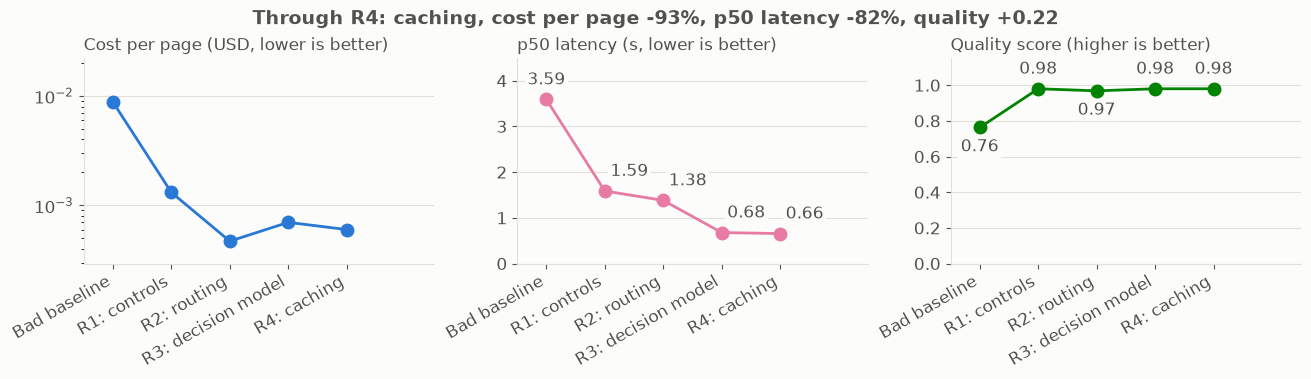

In [50]:
display(plot_progress(summary, upto_variant=CACHING))

## Round 5: split the workflow

```mermaid
flowchart LR
    subgraph SYNC["Sync path"]
        C["Classify"]:::after --> R["Route"]:::after --> D["Decide"]:::after
    end
    subgraph BATCH["Batch lane at 50 percent off"]
        L["Privilege log"]:::before
        Q["QA"]:::before
        T["Tags"]:::before
    end
    D -.-> L
    D -.-> Q
    D -.-> T
    classDef before fill:#e1e0d9,stroke:#52514e,stroke-width:1px,color:#1a1a18
    classDef after fill:#fcfcfb,stroke:#52514e,stroke-width:3px,color:#1a1a18
```

*Two lanes: the review path stays fast, and the slow jobs run later in Batch.*

**Symptom.** The privilege-log draft, QA sampling and production tags do not change the disposition, yet they sit in the review path.

In [51]:
symptoms(CACHING)

Round 4: caching: 0.1 tool calls per page (0.0 unneeded), 2,605 sync tokens, p50 0.66s, model cost $0.00060 per page
  escalation rate 33%; privileged leaks 0, PII leaks 0
  guardrail failures: none
  models used: {'gpt-6-luna': 21, 'gpt-6-luna, gpt-6.1-terra': 7, 'code': 2}


**Lever.** The review path stays classify, route, decide. The privilege-log draft, QA and tags become Batch jobs on `gpt-6-luna` at 50% off, run afterwards. Expected: lower p50 latency and synchronous cost. Total tokens stay level, and background cost is reported separately.

**Diff.** One Batch row per background task per page, written to `outputs/` and **not submitted**.

In [52]:
from collections import Counter

from doc_review_opt.batch import build_background_batch, write_batch_jsonl

batch_rows = build_background_batch(EVAL_SET, TRACES[SPLIT])
batch_path = write_batch_jsonl(batch_rows, OUTPUT_DIR / "background_batch.jsonl")
print(f"Wrote {len(batch_rows)} Batch rows to {batch_path.name}")
print("Rows per task:", dict(Counter(row["custom_id"].split(":")[1] for row in batch_rows)))
print(json.dumps(short_json(batch_rows[0], 140), indent=2))

Wrote 70 Batch rows to background_batch.jsonl
Rows per task: {'qa_sample': 30, 'production_tags': 30, 'privilege_log': 10}
{
  "custom_id": "ARC-000141:qa_sample",
  "method": "POST",
  "url": "/v1/responses",
  "body": {
    "model": "gpt-6-luna",
    "instructions": "Write a one-line quality-control note: does the coding of this page look consistent with the review protocol?",
    "input": "<page>\ndoc_id: ARC-000141\ncustodian: Dana Whitfield\nfrom: Finance Reporting\nto: -\ncc: -\n\nARCADIA FREIGHT -- Q3 2024 REVENUE SUMMARY (INTERNA... [414 chars]",
    "reasoning": {
      "effort": "none"
    },
    "text": {
      "verbosity": "low"
    },
    "max_output_tokens": 160
  }
}


Submission code is shown, never run. Batch has a 24-hour window and a 50% discount:

```python
batch_file = client.files.create(file=open(batch_path, "rb"), purpose="batch")
batch = client.batches.create(
    input_file_id=batch_file.id,
    endpoint="/v1/responses",
    completion_window="24h",
)
print(batch.id, batch.status)
```

**Re-measure.**

In [53]:
compare_rounds(CACHING, SPLIT)
delta_row(SPLIT)
show(
    summary[summary["variant"].isin([CACHING, SPLIT])][
        [
            "variant_label",
            "mean_sync_tokens",
            "mean_total_tokens",
            "p50_latency_s",
            "model_cost_per_page_usd",
        ]
    ].assign(
        sync_cost_per_page_usd=summary["sync_cost_per_page_usd"],
        background_cost_per_page_usd=summary["background_cost_per_page_usd"],
    )
)

Pages whose route changed: 0 of 30. Largest per-page cost changes:


,route_before,sync_tokens_before,latency_s_before,model_cost_usd_before,quality_score_before,route_after,sync_tokens_after,latency_s_after,model_cost_usd_after,quality_score_after,cost_saved_usd
doc_id,,,,,,,,,,,
ARC-000245,withhold,"2,049",0.65,$0.000125,0.98,withhold,"1,699",0.11,$0.000109,0.98,$+0.000015
ARC-000329,produce,"3,919",1.84,$0.002172,0.98,produce,"3,534",1.29,$0.002156,0.98,$+0.000015
ARC-000141,produce,"2,097",0.68,$0.000273,0.98,produce,"1,723",0.13,$0.000258,0.98,$+0.000015
ARC-000463,redact,"3,602",1.21,$0.000177,0.98,redact,"3,239",0.67,$0.000161,0.98,$+0.000015
ARC-000377,redact,"3,681",1.23,$0.000195,0.98,redact,"3,300",0.68,$0.000179,0.98,$+0.000015
ARC-000390,redact,"3,618",1.22,$0.000184,0.98,redact,"3,255",0.67,$0.000169,0.98,$+0.000015
ARC-000163,produce,"2,111",0.65,$0.000131,0.98,produce,"1,730",0.11,$0.000116,0.98,$+0.000015
ARC-000508,produce,"2,063",0.65,$0.000126,0.98,produce,"1,706",0.11,$0.000111,0.98,$+0.000015


,variant_label,mean_quality,policy_compliance,escalation_rate,mean_tool_calls,mean_extra_tool_calls,mean_sync_tokens,mean_total_tokens,mean_cached_tokens,p50_latency_s,model_cost_per_page_usd,cost_per_page_usd,mean_sync_tokens_delta_vs_previous,mean_total_tokens_delta_vs_previous,p50_latency_s_delta_vs_previous,model_cost_per_page_usd_delta_vs_previous,cost_per_page_usd_delta_vs_previous,quality_delta_vs_previous
5,Round 5: split workflow,0.98,100%,33%,0.1,0.0,"2,267","2,759","1,358",0.11,$0.00060,$0.501,-338,+154,-0.55,$-0.00000,$-0.000,+0.00


,variant_label,mean_sync_tokens,mean_total_tokens,p50_latency_s,model_cost_per_page_usd,sync_cost_per_page_usd,background_cost_per_page_usd
4,Round 4: caching,"2,605","2,605",0.66,$0.00060,$0.000602,$0.000000
5,Round 5: split workflow,"2,267","2,759",0.11,$0.00060,$0.000534,$0.000067


**Quality gate.** The split moves work out of the review path; it must not move any decision.

In [54]:
quality_gate(CACHING, SPLIT)

Hard gates: privileged pages produced = 0, PII left in produced text = 0
Guardrail pass rate: 100% (floor 95%); failures: none
Mean quality: 0.98 -> 0.98
Round 5: split workflow: ACCEPTED


**Tradeoff.** Synchronous latency drops (compare p50 with Round 4) while total tokens stay level, at half price. It adds a job queue, result storage and failure handling, so split only work that can wait.

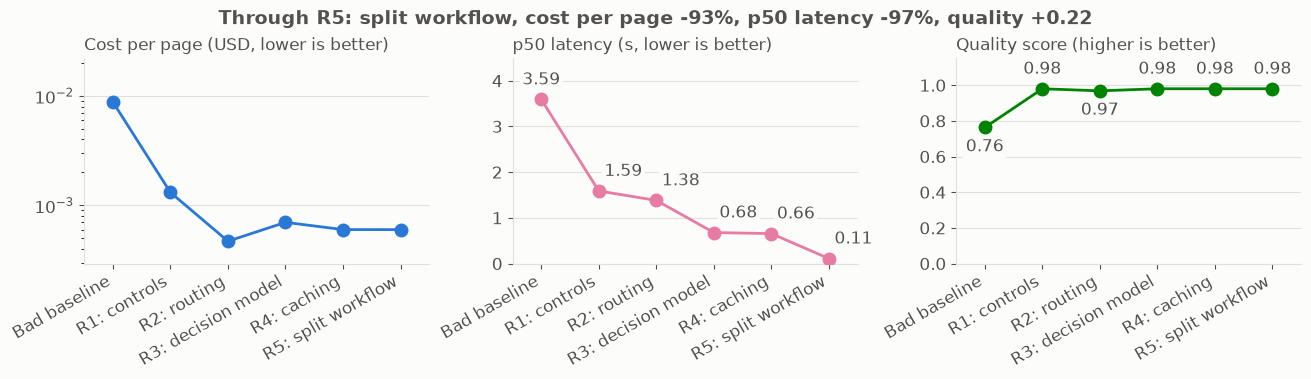

In [55]:
display(plot_progress(summary, upto_variant=SPLIT))

## Quality across rounds

Three views of the same gate: which versions pass, where the pages end up, and which pages each version gets wrong.

**How to read it.** Each bar is one version. Green passes the gate (at least the floor and zero leaks); red is rejected. The dashed line is the floor.

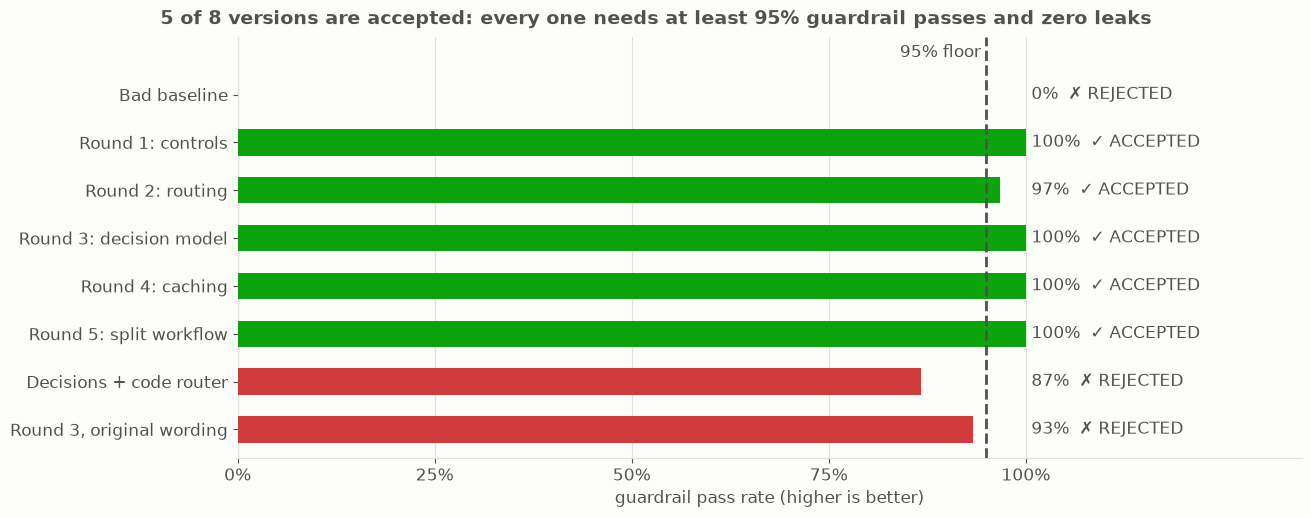

In [56]:
from doc_review_opt.reporting import plot_quality_gate

gate_rows = []
for variant in VARIANT_ORDER + EXTRA_VARIANTS:
    rate, accepted = gate_result(variant)
    gate_rows.append({"label": VARIANT_LABELS[variant], "pass_rate": rate, "accepted": accepted})
display(plot_quality_gate(pd.DataFrame(gate_rows), GUARDRAIL_FLOOR))

**How to read it.** Each bar is 100% of the pages. The top bar is what the labels expect; a good round matches it.

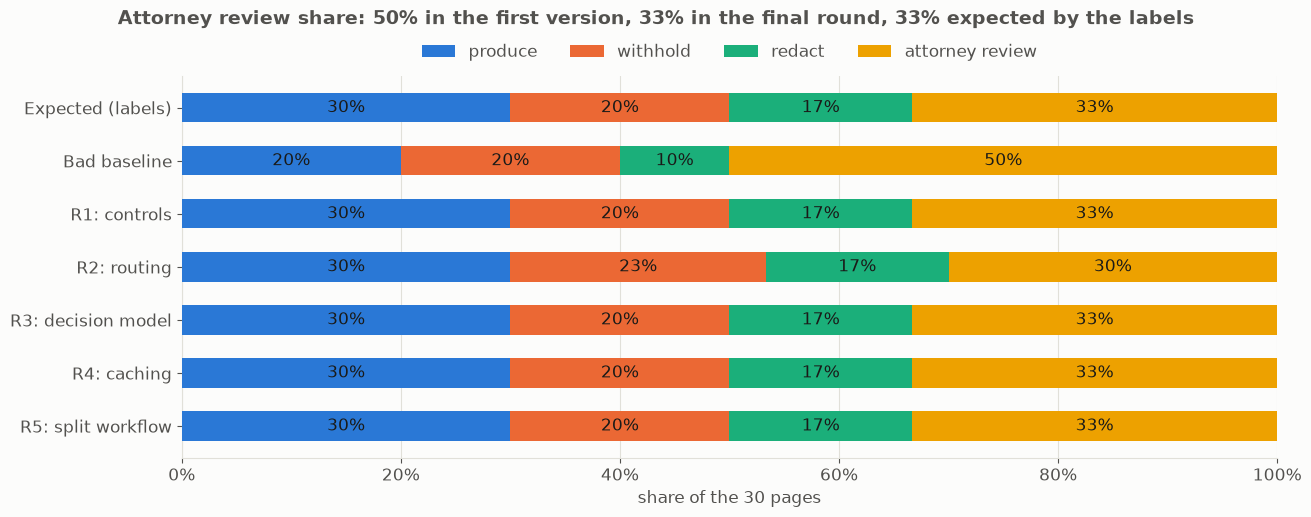

In [57]:
from doc_review_opt.reporting import plot_route_mix

display(plot_route_mix(frame, VARIANT_ORDER))

**How to read it.** One row per page, one column per version. Green dot: right route. Red cross: wrong route. Red triangle: a leak.

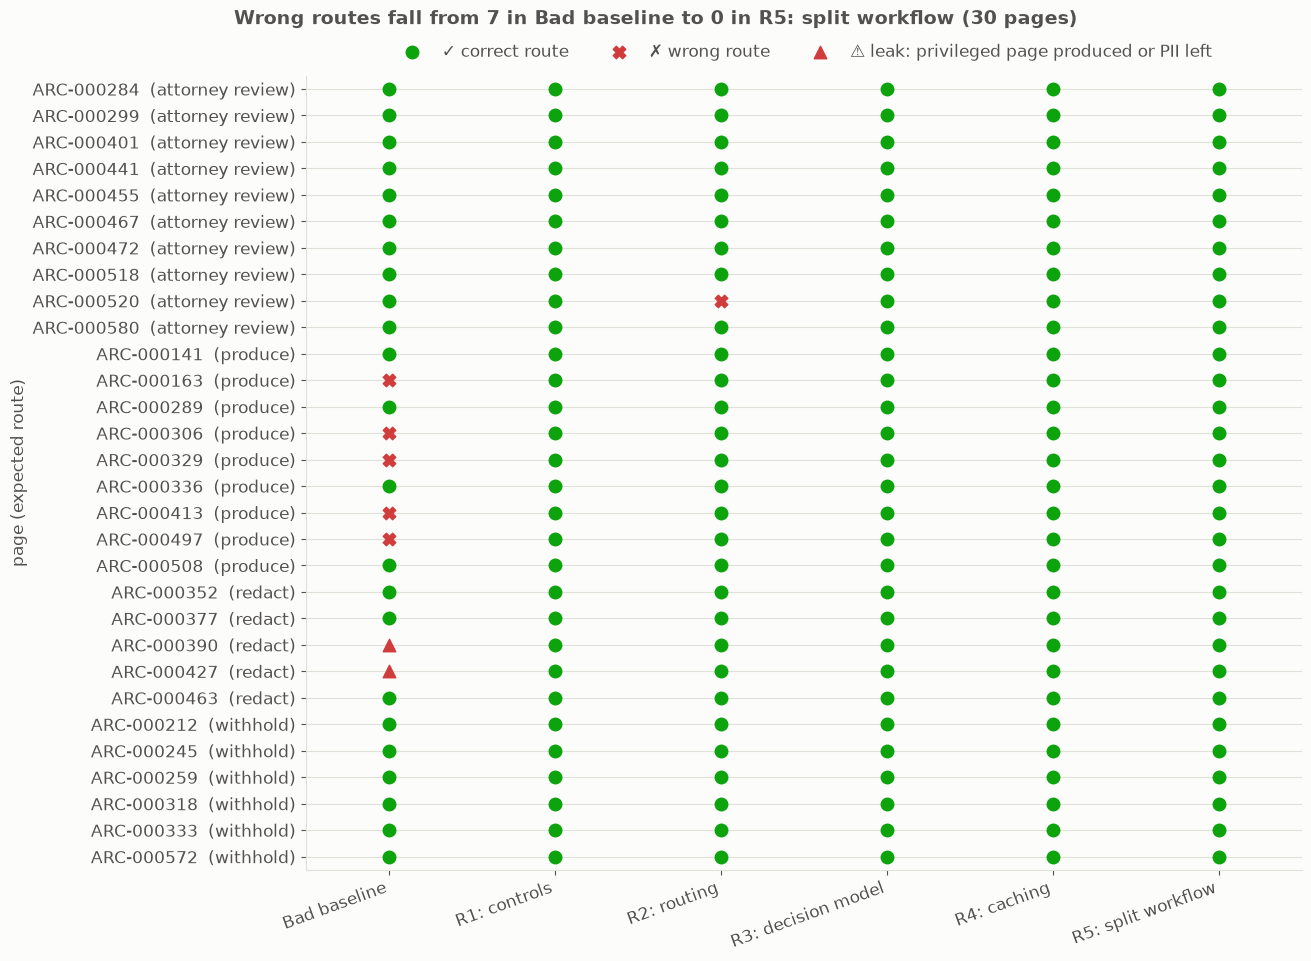

In [58]:
from doc_review_opt.reporting import plot_scorecard

display(plot_scorecard(frame, VARIANT_ORDER))

## Human in the loop: attorney review

```mermaid
sequenceDiagram
    participant G as Graph
    participant A as Attorney
    participant R as Result
    G->>A: interrupt - ids and scores, no page text
    A->>G: resume - decision
    G->>G: redact first if PII, then produce
    G->>R: final route
```

*Follow the arrows: the graph pauses, only ids and scores go out, and the decision comes back.*

Every page routed to attorney review pauses the graph with `interrupt()` and resumes with the attorney's decision. The payload holds IDs, the reason and scores only, never page text, so a review queue can be logged without leaking privileged content. The next cells inspect the payloads, assert none contains page text, and resume with scripted decisions.

In [59]:
from langgraph.types import Command

from doc_review_opt.runs import scripted_attorney_decisions

escalating = [page for page in EVAL_SET if page.labels.must_escalate][:3]
clean = [page for page in EVAL_SET if not page.labels.must_escalate][:1]
hitl_pages = escalating + clean
hitl_classifier, hitl_redactor = build_simulated_engines(
    VARIANTS[DECISION_MODEL], hitl_pages, CALIBRATED_POLICY
)
hitl_graph = build_review_graph(
    hitl_classifier, hitl_redactor, review_checkpointer(), policy=CALIBRATED_POLICY
)
hitl_config = {"configurable": {"thread_id": "attorney-demo"}}
paused = await hitl_graph.ainvoke({"pages": hitl_pages, "results": []}, hitl_config)
interrupts = paused["__interrupt__"]
payloads = [pending.value for pending in interrupts]
print(f"{len(hitl_pages)} pages in, {len(paused['results'])} finished, {len(payloads)} waiting for an attorney")
display(pd.DataFrame(payloads))

4 pages in, 1 finished, 3 waiting for an attorney


,doc_id,reason,privileged,responsive_score,responsive_confidence
0,ARC-000284,privilege_above_threshold,0.899668,1.859382,0.625969
1,ARC-000299,privilege_above_threshold,0.904058,1.833025,0.601289
2,ARC-000401,privilege_above_threshold,0.908829,1.887176,0.606279


In [60]:
SNIPPET_CHARS = get_settings().quality.snippet_chars
for payload in payloads:
    page = PAGE_BY_ID[payload["doc_id"]]
    assert page.text[:SNIPPET_CHARS] not in json.dumps(payload)
    assert set(payload) == {"doc_id", "reason", "privileged", "responsive_score", "responsive_confidence"}
print("Checked: no interrupt payload contains page text.")

Checked: no interrupt payload contains page text.


In [61]:
attorney_decisions = scripted_attorney_decisions(hitl_pages)
resume = {pending.id: attorney_decisions[pending.value["doc_id"]] for pending in interrupts}
final = await hitl_graph.ainvoke(Command(resume=resume), hitl_config)
display(
    pd.DataFrame(
        [
            result.model_dump(
                include={"doc_id", "route", "decision", "escalated", "attorney_decision", "redacted", "reason"}
            )
            for result in final["results"]
        ]
    )
)

,doc_id,decision,route,redacted,escalated,attorney_decision,reason
0,ARC-000284,withhold,attorney_review,False,True,withhold,privilege_above_threshold
1,ARC-000299,withhold,attorney_review,False,True,withhold,privilege_above_threshold
2,ARC-000401,withhold,attorney_review,False,True,withhold,privilege_above_threshold
3,ARC-000141,produce,produce,False,False,NaN,clean_responsive


## Tradeoffs and scenario mapping

This section zooms out. It asks **when a decision model is better and when a step still needs an LLM**, using a step matrix, an engine comparison, a threshold sweep and cascade economics. Then it maps architectures to operating scenarios.

### Decisions or LLM?

```mermaid
flowchart TD
    Q1["Need generated text?"] -->|"yes"| L["Use an LLM"]
    Q1 -->|"no"| Q2["Need tool calls or<br/>your own JSON schema?"]
    Q2 -->|"yes"| L
    Q2 -->|"no"| Q3["Need a typed answer, fast and auditable?<br/>probability, choice or score"]
    Q3 -->|"yes"| D["Use Decisions"]:::decisions
    Q3 -->|"no"| L
    D --> R["Route in code<br/>fail safe to attorney"]
    classDef decisions fill:#2a78d6,stroke:#52514e,stroke-width:1px,color:#1a1a18
```

*Start at the top and answer in order; the first yes decides the engine.*

The matrix goes through every step of the agent and names the engine that fits.

In [62]:
from doc_review_opt.tradeoffs import STEP_MATRIX, WHEN_TO_USE

display(pd.DataFrame(STEP_MATRIX))

,step,fits,why
0,Responsiveness rubric,Decisions,"A fixed 0-2 rubric is a typed score: one cheap call, no text to write."
1,Privilege predicate,Decisions,A yes/no with a probability feeds a low escalation threshold; the cascade sends the ambiguous band to a stronger model.
2,PII presence,Decisions,Deciding whether personal data is present is a predicate; finding the spans is not (Decisions cannot extract to your own schema).
3,Near-duplicate check,Code,An index lookup is deterministic and free; no model should do it.
4,Escalation gate,Code,Thresholds over typed answers are plain code you can test and audit.
5,Redaction rewrite,LLM,Writing the page with spans replaced is generation; Decisions only answers questions.
6,Privilege-log drafting,LLM,A log entry is free text with an explanation; Decisions cannot write one.
7,QA tags,LLM,Tags and notes are generated text; batch them off the page path.


**Engine comparison.** The same 30 pages, graph and router, with only the classifier swapped: Decisions, the same three questions on `gpt-6-luna` and on `gpt-6.1-terra` as LLMs, and the controlled agent. Accuracy is route accuracy against labels; agreement is with Decisions. The first table uses the default thresholds, the second the thresholds calibrated for Decisions. Note what moves when only thresholds change.

In [63]:
tables = []
for name, runs in (("default", engine_runs_default), ("calibrated", engine_runs_calibrated)):
    tables.append(engine_comparison_table(runs).drop(columns="label").assign(policy=name))
both_policies = pd.concat(tables, ignore_index=True)
display(
    both_policies[
        [
            "policy",
            "engine",
            "accuracy_vs_labels",
            "agreement_vs_decisions",
            "cost_per_100k_pages_usd",
            "p50_latency_s",
            "escalation_rate",
            "privileged_leaks",
            "pii_leaks",
        ]
    ].style.format(ENGINE_FORMATS, na_rep="-")
)

,policy,engine,accuracy_vs_labels,agreement_vs_decisions,cost_per_100k_pages_usd,p50_latency_s,escalation_rate,privileged_leaks,pii_leaks
0,default,decisions,50%,100%,$18,0.13,83%,0,0
1,default,llm-luna,80%,70%,$21,0.81,53%,0,1
2,default,llm-terra,97%,50%,$203,1.18,33%,0,0
3,default,agent,100%,50%,$131,1.59,33%,0,0
4,calibrated,decisions,83%,100%,$18,0.13,50%,0,0
5,calibrated,llm-luna,80%,97%,$21,0.81,50%,0,1
6,calibrated,llm-terra,97%,83%,$203,1.18,33%,0,0
7,calibrated,agent,100%,83%,$131,1.59,33%,0,0


**Live engine comparison (optional).** With `RUN_LIVE_API_CALLS=true` the four engines run on real APIs over `LIVE_PAGE_LIMIT` pages. With `LANGSMITH_TRACING=true` each run is one trace named `doc_review::<engine>`. The $1 budget still applies.

In [64]:
from doc_review_opt.tradeoffs import live_engine_comparison, plot_engine_tradeoff

live_engine_runs = {}
if RUN_LIVE_API_CALLS:
    try:
        live_engine_runs = await live_engine_comparison(
            LIVE_PAGES, client=client, budget=budget
        )
    except BudgetExceededError as error:
        print("Stopped by the budget:", error)
    if live_engine_runs:
        live_engine_table = engine_comparison_table(live_engine_runs)
        display(live_engine_table.drop(columns="label").style.format(ENGINE_FORMATS, na_rep="-"))
        for name, run in live_engine_runs.items():
            print(f"{name}: {run.trace_url or 'LangSmith tracing is off'}")
    print(f"Running spend: ${budget.total_usd:.4f} of ${budget.limit_usd:.2f}")
else:
    print("Dry-run mode. Set OPENAI_API_KEY and RUN_LIVE_API_CALLS=true to compare the engines on the real APIs.")

Dry-run mode. Set OPENAI_API_KEY and RUN_LIVE_API_CALLS=true to compare the engines on the real APIs.


**Cost against latency.** One dot per engine; the bottom-left corner is better. In the simulation, Decisions is cheap and fast, and the strongest LLM costs roughly ten times more per page (accuracy is in the table above). The Decisions profile is an assumption, so read the shape, not the exact values. Live (2026-11-18, 6 pages), Decisions was fastest but not cheapest: `gpt-6-luna` as an LLM cost about 0.6x as much per page.

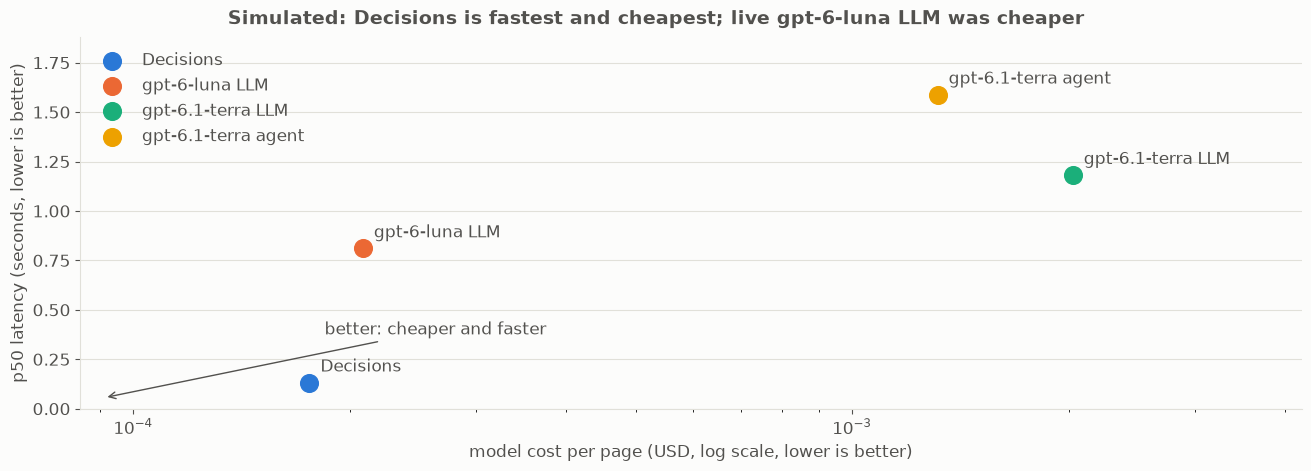

In [65]:
display(plot_engine_tradeoff(engine_comparison_table(engine_runs_calibrated)))

**Threshold sweep.** A lower privilege threshold escalates more and leaks fewer privileged pages. Each engine needs its own operating point. **How to read it:** each line is one engine; a red cross marks a threshold where a privileged page would be produced.

escalation_rate


engine,decisions,llm-luna,llm-terra
privilege_threshold,,,
0.05,93%,63%,63%
0.10,83%,53%,33%
0.20,83%,53%,33%
0.30,83%,53%,33%
0.40,83%,53%,33%
0.50,83%,50%,33%
0.60,83%,50%,33%
0.70,83%,50%,33%
0.80,83%,50%,27%


privileged_leaks


engine,decisions,llm-luna,llm-terra
privilege_threshold,,,
0.05,0,0,0
0.10,0,0,0
0.20,0,0,0
0.30,0,0,0
0.40,0,0,0
0.50,0,1,0
0.60,0,1,0
0.70,0,1,0
0.80,0,1,2


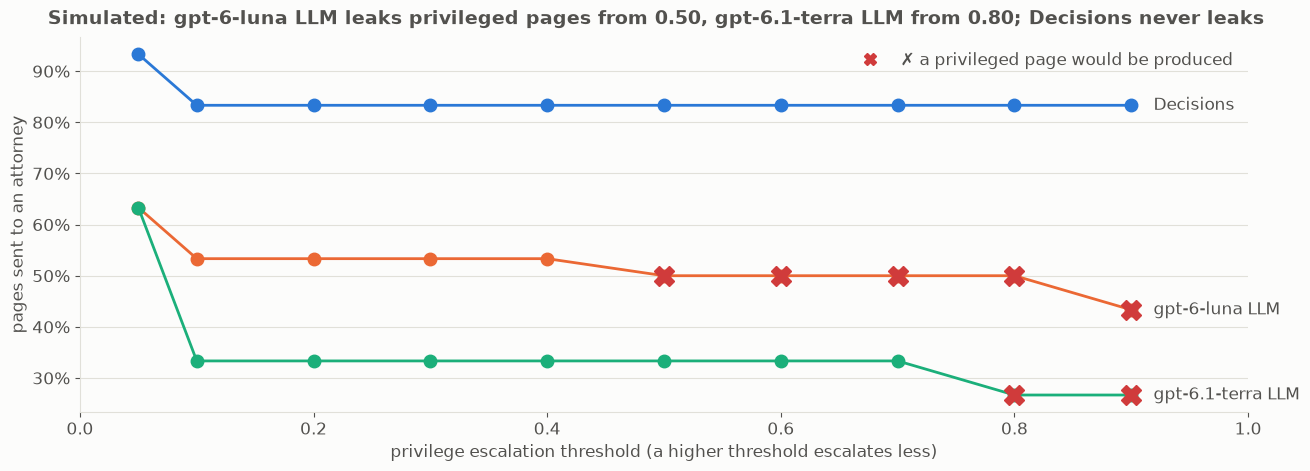

In [66]:
from doc_review_opt.tradeoffs import plot_threshold_sweep, threshold_sweep

sweep = threshold_sweep(engine_runs_default, EVAL_SET)
for column, fmt in (("escalation_rate", "{:.0%}"), ("privileged_leaks", "{:.0f}")):
    print(column)
    display(
        sweep.pivot(index="privilege_threshold", columns="engine", values=column)
        .style.format(fmt)
        .format_index("{:.2f}")
    )
display(plot_threshold_sweep(sweep))

**Cascade economics (simulated).** Decisions alone has the lowest model cost, but its extra mistakes cost attorney time. A `gpt-6.1-terra` second opinion on the ambiguous band costs a little more and cuts escalations. `gpt-6.1-terra` on everything costs several times more for no better quality. `blended` includes attorney time.

In [67]:
from doc_review_opt.tradeoffs import cascade_analysis

cascade = await cascade_analysis()
display(
    cascade.style.format(
        {
            "model_cost_per_page_usd": "${:.6f}",
            "attorney_cost_per_page_usd": "${:.3f}",
            "blended_cost_per_page_usd": "${:.3f}",
            "mean_quality": "{:.2f}",
        }
    )
)

,arm,model_cost_per_page_usd,attorney_escalations,attorney_cost_per_page_usd,blended_cost_per_page_usd,mean_quality
0,Decisions only,$0.000232,14,$0.700,$0.700,0.93
1,Decisions + terra cascade,$0.000701,10,$0.500,$0.501,0.98
2,Terra only,$0.002027,10,$0.500,$0.502,0.97


**Where Decisions fits and where an LLM is needed.**

In [68]:
display(pd.DataFrame(WHEN_TO_USE))

,factor,use_decisions_when,use_an_llm_when
0,Output,"The answer is a typed route: yes/no, choice or score.",The output is generated text or your own extraction schema.
1,Volume,"Millions of pages and the alternative is a large LLM (live, 6 pages: 4-6x cheaper than gpt-6.1-terra; about 1.7x pricier than gpt-6-luna as an LLM).","Volume is low enough that per-call cost does not matter, or the smallest LLM is accurate enough."
2,Latency,"The page path is on a deadline (live, 6 pages: ~6x faster than gpt-6-luna and 6-8x faster than gpt-6.1-terra at p50).",A second or two per page is acceptable.
3,Tools,No tool calls are needed; code does the lookups.,The model has to choose and call tools.
4,Explanations,A probability is enough for routing.,"A reviewer needs a reason, such as a privilege-log entry."
5,Model choice,gpt-6-luna is accurate enough for the rubric.,You need a stronger model; Decisions only supports gpt-6-luna.
6,Refusals,You treat a refused answer as escalate-to-attorney.,You can retry or rephrase on a refusal.
7,Confidence,You recalibrate thresholds on your own labelled split.,You cannot recalibrate: confidence does not port between engines.


### Candidate architectures

Each row turns a sprint outcome into an architecture: models, tools, caching, and whether slow work is split off.

In [69]:
from doc_review_opt.scenarios import (
    ARCHITECTURE_OPTIONS,
    OPERATING_SCENARIOS,
    best_fit,
    scenario_map,
)

display(pd.DataFrame(ARCHITECTURE_OPTIONS).T)

,label,variant,models,tools,cache,workflow,best_for
baseline_one_big_agent,One big agent,00_bad_baseline,gpt-6.1-terra for every step,all tools exposed,none,all work synchronous,prototype smell test only
controlled_terra,Controlled terra agent,01_prompt_tool_context_controls,gpt-6.1-terra for review,allowed tools by page type,none,some follow-up still synchronous,high-risk launch while routing is unproven
llm_routed,LLM routed luna/terra,02_model_routing,"gpt-6-luna triage and routine pages, gpt-6.1-terra for high risk",allowed tools by routed path,none,some follow-up still synchronous,mixed matters with moderate repeat traffic
decisions_code_router,Decisions + code router,03a_router_only,"Decisions on gpt-6-luna, code router, luna redaction","code pre-lookup, no model tools",none,some follow-up still synchronous,typed routing at volume when thresholds are calibrated
decisions_llm_cascade,Decisions + LLM cascade,03_decision_model,"Decisions on gpt-6-luna, gpt-6.1-terra second opinion in the ambiguous band","code pre-lookup, no model tools",none,some follow-up still synchronous,matters where attorney time costs more than a terra call
decisions_cache,Decisions + cache,04_prompt_caching,"Decisions on gpt-6-luna, terra second opinion, luna redaction","code pre-lookup, no model tools",stable protocol prefix,some follow-up still synchronous,rolling productions that reuse one protocol
decisions_split_no_cache,"Decisions split, no cache",,"Decisions on gpt-6-luna, terra second opinion, luna Batch background","code pre-lookup, no model tools",none,"page path sync, privilege log, QA and tags async",low-repeat matters that still need async follow-up work
balanced_split,Balanced split workflow,05_split_workflow,"Decisions on gpt-6-luna, terra second opinion, luna Batch background","code pre-lookup, no model tools",stable protocol prefix,"page path sync, privilege log, QA and tags async",mature repeated-protocol review programs


### Scenario sweet spots

Scenarios differ in what they cannot compromise on: quality, policy, latency, budget, escalation rate, async needs and traffic repeat (caching needs high repeat). The fit score adds or subtracts points per constraint:

- quality +3 / -4, policy +3 / -5
- latency and budget +2 / -2
- async +2 / -1, escalation rate +2 / -2
- a cache-locality penalty, and +1 if recommended

The table shows the best-scoring architecture per scenario.

In [70]:
display(
    pd.DataFrame(OPERATING_SCENARIOS)[
        [
            "scenario",
            "description",
            "quality_floor",
            "policy_floor",
            "p50_latency_target_s",
            "monthly_budget_100k_pages_usd",
            "max_escalation_rate",
            "needs_async",
            "cache_locality",
        ]
    ]
)
SCENARIO_FORMATS = {
    "quality": "{:.2f}",
    "policy_compliance": "{:.0%}",
    "escalation_rate": "{:.0%}",
    "p50_latency_s": "{:.2f}",
    "cost_per_page_usd": "${:.5f}",
    "monthly_cost_at_100k_pages": "${:,.0f}",
}
display(best_fit(full_summary).reset_index(drop=True).style.format(SCENARIO_FORMATS))

,scenario,description,quality_floor,policy_floor,p50_latency_target_s,monthly_budget_100k_pages_usd,max_escalation_rate,needs_async,cache_locality
0,Second-request deadline,"Huge volume, a court deadline, and cost per page matters most.",0.9,0.90,2.0,100.0,0.40,True,high
1,Privilege-heavy custodians,Counsel's own mailboxes: privilege misses are unacceptable.,0.9,1.00,3.0,200.0,0.60,True,medium
2,PII/HIPAA-heavy matter,Health and account data everywhere: a PII leak is the failure to avoid.,0.9,1.00,3.0,150.0,0.50,True,medium
3,Small internal investigation,"A few thousand pages, quality over unit cost, little repetition.",0.9,0.95,4.0,400.0,0.70,False,low
4,"Rolling production, repeated protocol",Weekly productions under one protocol: the prefix repeats constantly.,0.9,0.95,2.0,80.0,0.45,True,high
5,Low-repeat long tail of matters,"Many small matters, each with its own protocol: cache hits are rare.",0.9,0.95,2.5,120.0,0.50,True,low


,scenario,architecture,label,score,quality,policy_compliance,escalation_rate,p50_latency_s,cost_per_page_usd,monthly_cost_at_100k_pages,failed_constraints
0,Second-request deadline,balanced_split,Balanced split workflow,15,0.98,100%,33%,0.11,$0.00060,$60,none
1,Privilege-heavy custodians,decisions_split_no_cache,"Decisions split, no cache",14,0.98,100%,33%,0.50,$0.00070,$70,none
2,PII/HIPAA-heavy matter,decisions_split_no_cache,"Decisions split, no cache",15,0.98,100%,33%,0.50,$0.00070,$70,none
3,Small internal investigation,llm_routed,LLM routed luna/terra,15,0.97,97%,30%,1.38,$0.00047,$47,none
4,"Rolling production, repeated protocol",balanced_split,Balanced split workflow,15,0.98,100%,33%,0.11,$0.00060,$60,none
5,Low-repeat long tail of matters,decisions_split_no_cache,"Decisions split, no cache",15,0.98,100%,33%,0.50,$0.00070,$70,none


### Full combination map for one scenario

Every architecture scored against one scenario, so you can see which constraint each loser fails. This one is the second-request deadline: huge volume, a court deadline, and cost per page matters most.

In [71]:
deadline = scenario_map(full_summary)
deadline = deadline[deadline["scenario"] == OPERATING_SCENARIOS[0]["scenario"]]
display(
    deadline.sort_values("score", ascending=False)
    .drop(columns="scenario")
    .reset_index(drop=True)
    .style.format(SCENARIO_FORMATS)
)

,architecture,label,score,quality,policy_compliance,escalation_rate,p50_latency_s,cost_per_page_usd,monthly_cost_at_100k_pages,failed_constraints
0,balanced_split,Balanced split workflow,15,0.98,100%,33%,0.11,$0.00060,$60,none
1,decisions_split_no_cache,"Decisions split, no cache",14,0.98,100%,33%,0.50,$0.00070,$70,none
2,decisions_cache,Decisions + cache,12,0.98,100%,33%,0.66,$0.00060,$60,async split
3,llm_routed,LLM routed luna/terra,11,0.97,97%,30%,1.38,$0.00047,$47,async split
4,decisions_llm_cascade,Decisions + LLM cascade,11,0.98,100%,33%,0.68,$0.00070,$70,async split
5,controlled_terra,Controlled terra agent,7,0.98,100%,33%,1.59,$0.00131,$131,"budget, async split"
6,decisions_code_router,Decisions + code router,-1,0.93,87%,47%,0.67,$0.00023,$23,"policy, async split, escalation rate"
7,baseline_one_big_agent,One big agent,-16,0.76,77%,50%,3.59,$0.00879,$879,"quality, policy, latency, budget, async split, escalation rate"


## Monitoring, evals and guardrails

Deterministic guardrails run on every trace and need no model. They check:

- **hard gates:** a privileged page produced, personal data in produced text
- **outcome:** responsive page withheld, non-responsive page produced, escalation mismatch, unnecessary attorney review
- **interface:** page text in an interrupt payload, unparseable reply, unescalated classifier error
- **efficiency:** too many unnecessary tool calls

In [72]:
from doc_review_opt.evaluation import evaluate_answer_traces, summarize_answer_evals

main_traces = [trace for trace in traces if trace.variant in VARIANT_ORDER]
guard_results = await evaluate_answer_traces(EVAL_SET, main_traces)
guard_summary = guard_results.groupby("variant_label", sort=False).agg(
    pages=("doc_id", "count"),
    deterministic_pass_rate=("deterministic_passed", "mean"),
)
display(guard_summary.style.format({"deterministic_pass_rate": "{:.0%}"}))
failing = guard_results[~guard_results["deterministic_passed"]]
print(f"{len(failing)} of {len(guard_results)} traces fail at least one check. Failing rows, first 12:")
display(failing[["variant_label", "doc_id", "deterministic_failures"]].head(12))

,pages,deterministic_pass_rate
variant_label,,
Bad baseline,30,0%
Round 1: controls,30,100%
Round 2: routing,30,97%
Round 3: decision model,30,100%
Round 4: caching,30,100%
Round 5: split workflow,30,100%


31 of 180 traces fail at least one check. Failing rows, first 12:


,variant_label,doc_id,deterministic_failures
0,Bad baseline,ARC-000141,too_many_unnecessary_tools
1,Bad baseline,ARC-000163,"escalation_mismatch, unnecessary_attorney_review, unparseable_agent_output, too_many_unnecessary_tools"
2,Bad baseline,ARC-000212,too_many_unnecessary_tools
3,Bad baseline,ARC-000245,too_many_unnecessary_tools
4,Bad baseline,ARC-000259,too_many_unnecessary_tools
5,Bad baseline,ARC-000284,too_many_unnecessary_tools
6,Bad baseline,ARC-000289,too_many_unnecessary_tools
7,Bad baseline,ARC-000299,too_many_unnecessary_tools
8,Bad baseline,ARC-000306,"escalation_mismatch, unnecessary_attorney_review, too_many_unnecessary_tools"
9,Bad baseline,ARC-000318,too_many_unnecessary_tools


### Optional: LLM judge

The judge (`gpt-6.1-terra`, strict `{passed, reason}` schema, no retries) grades whether the outcome is defensible. It never overrides a deterministic failure: a trace passes only if **both** pass. It runs on the simulated traces for `LIVE_PAGE_LIMIT` pages across six variants, charged to the $1 budget. Without `RUN_LLM_JUDGE=true` and `OPENAI_API_KEY`, the summary shows only the deterministic pass rate.

In [73]:
judge_ids = {page.doc_id for page in LIVE_PAGES}
if RUN_LLM_JUDGE:
    judge_traces = [trace for trace in main_traces if trace.doc_id in judge_ids]
    try:
        judge_results = await evaluate_answer_traces(
            EVAL_SET, judge_traces, client=judge_client, budget=budget
        )
    except BudgetExceededError as error:
        print("Stopped by the budget:", error)
        judge_results = guard_results
    print(f"Judged {len(judge_traces)} traces. Running spend: ${budget.total_usd:.4f} of ${budget.limit_usd:.2f}")
else:
    judge_results = guard_results
    print("Dry-run mode. Set OPENAI_API_KEY and RUN_LLM_JUDGE=true to grade the simulated traces with the judge.")
display(
    summarize_answer_evals(judge_results).style.format(
        {
            "deterministic_pass_rate": "{:.0%}",
            "judge_coverage": "{:.0%}",
            "judge_pass_rate": "{:.0%}",
            "both_pass_rate": "{:.0%}",
            "known_judge_cost_usd": "${:.4f}",
        },
        na_rep="-",
    )
)

Dry-run mode. Set OPENAI_API_KEY and RUN_LLM_JUDGE=true to grade the simulated traces with the judge.


,variant,variant_label,pages,deterministic_pass_rate,judge_graded,judge_coverage,judge_errors,judge_pass_rate,both_pass_rate,known_judge_cost_usd
0,00_bad_baseline,Bad baseline,30,0%,0,0%,0,-,-,-
1,01_prompt_tool_context_controls,Round 1: controls,30,100%,0,0%,0,-,-,-
2,02_model_routing,Round 2: routing,30,97%,0,0%,0,-,-,-
3,03_decision_model,Round 3: decision model,30,100%,0,0%,0,-,-,-
4,04_prompt_caching,Round 4: caching,30,100%,0,0%,0,-,-,-
5,05_split_workflow,Round 5: split workflow,30,100%,0,0%,0,-,-,-


## Optional: full live run

With `RUN_LIVE_API_CALLS=true` every variant runs on the real APIs over the same `LIVE_PAGE_LIMIT` pages, with async fan-out and the shared budget. The graph, router and checks match the simulation, so the same summary applies. It stops cleanly at the $1 cap. With `LANGSMITH_TRACING=true` each variant is one trace and the URLs are printed.

Live numbers differ from the simulation because latency, tokens, caching and accuracy are measured. On a few pages they are anecdotes, not a benchmark.

In [74]:
live_runs = {}
if RUN_LIVE_API_CALLS:
    for variant in VARIANT_ORDER:
        try:
            live_runs[variant] = await run_live_variant(
                variant, LIVE_PAGES, client=client, budget=budget
            )
        except BudgetExceededError as error:
            print(f"Stopped before finishing {variant}: {error}")
            break
        print(f"{variant}: spend so far ${budget.total_usd:.4f} of ${budget.limit_usd:.2f}")
    if live_runs:
        live_traces = [trace for run in live_runs.values() for trace in run.traces]
        live_summary = summarize(traces_frame(live_traces))
        show(
            live_summary[
                [
                    "variant_label",
                    "pages",
                    "mean_quality",
                    "route_accuracy",
                    "escalation_rate",
                    "privileged_leaks",
                    "pii_leaks",
                    "mean_sync_tokens",
                    "p50_latency_s",
                    "model_cost_per_page_usd",
                ]
            ]
        )
        display(pd.DataFrame([{"variant": v, "trace_url": run.trace_url} for v, run in live_runs.items()]))
else:
    print("Dry-run mode. Set OPENAI_API_KEY and RUN_LIVE_API_CALLS=true to run every variant on the real APIs.")

Dry-run mode. Set OPENAI_API_KEY and RUN_LIVE_API_CALLS=true to run every variant on the real APIs.


## What the live run showed

Live run, 2026-11-18, 6 pages (`LIVE_PAGE_LIMIT`), $0.18 of the $1 cap, no errors. Measured, not modeled, and six pages are an anecdote. Anything above not labelled live is simulated.

| Round | Quality | Escalation | Sync tokens | p50 (s) | Model $/page |
|---|---|---|---|---|---|
| Bad baseline | 0.84 | 33% | 16,996 | 10.92 | 0.02243 |
| R1 controls | 0.98 | 17% | 942 | 2.96 | 0.00112 |
| R2 routing | 0.95 (one misroute) | 17% | 1,326 | 4.00 | 0.00039 |
| R3 decision model | 0.98 | 17% | 1,772 | 0.45 | 0.00008 |
| R4 caching | 0.98 | 17% | 1,772 | 0.43 | 0.00021 |
| R5 split | 0.98 | 17% | 1,772 | 0.34 | 0.00008 |

Zero privileged or PII leaks in every round. Judge (`gpt-6.1-terra`): the baseline passed the judge on 83% of pages but the deterministic checks on 0%; Rounds 1 to 5 passed both on 100%.

**Live engine comparison** (same 6 pages):

| Engine | Accuracy | Escalation | Model $/page | p50 (s) |
|---|---|---|---|---|
| Decisions | 100% | 17% | 0.00019 | 0.38 |
| `gpt-6-luna` as an LLM | 100% | 17% | 0.00011 | 2.26 |
| `gpt-6.1-terra` as an LLM | 100% | 17% | 0.00073 | 3.03 |
| Controlled agent (`gpt-6.1-terra`) | 100% | 17% | 0.00118 | 2.33 |

Live Decisions privileged probability on the two attorney-cc'd mails (original wording / protocol wording): ARC-000306 0.02 / 0.00; ARC-000413 0.00 / 0.00.

**Where live diverged from the simulation.**

1. **Round 2 was slower, not faster.** p50 4.00s against 2.96s, and one misroute (quality 0.95). Model cost per page still fell ($0.00039 against $0.00112).
2. **Decisions won on latency, not always price.** About 6x faster but 1.7x pricier than `gpt-6-luna` as an LLM; 4 to 6x cheaper and 6 to 8x faster than `gpt-6.1-terra`. Its other benefits are calibratable probabilities and an auditable router.
3. **The wording lever was not needed.** The real API scores cc'd mail near 0 with either wording, so the simulated over-escalation (about 0.3) did not reproduce. The protocol wording stays because it is free.
4. **Round 4 caching cost more** on 6 pages ($0.00021 against $0.00008 per page). It pays only at volume.

**How to read it.** Blue is the simulation, orange is the measured live run. The recorded values are the table above; a live session in this notebook replaces them.

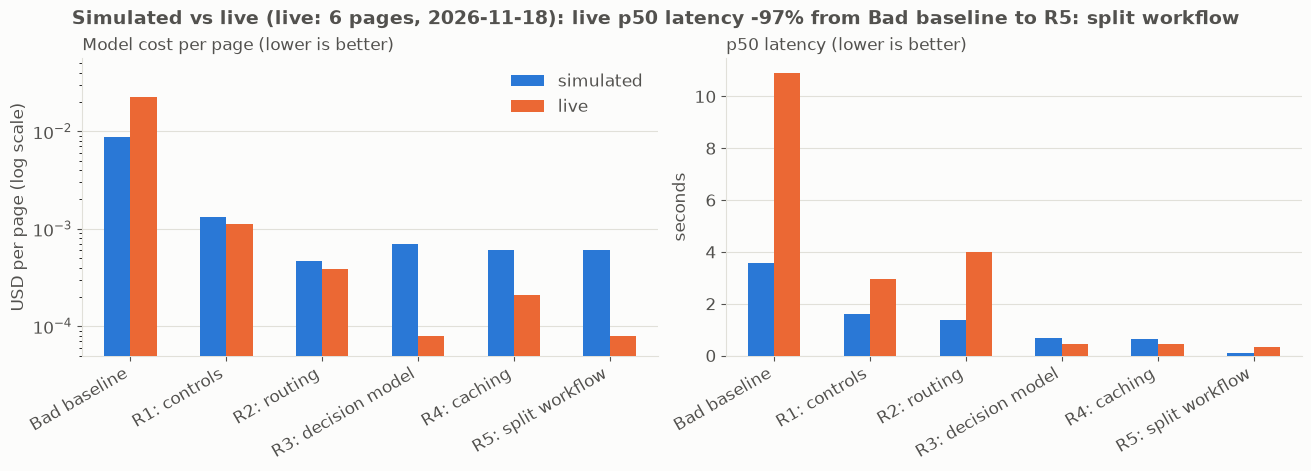

In [75]:
from doc_review_opt.reporting import plot_sim_vs_live, recorded_live_note, recorded_live_summary

if live_runs:
    live_view, live_note = live_summary, f"live: {LIVE_PAGE_LIMIT} pages, this session"
else:
    live_view, live_note = recorded_live_summary(), recorded_live_note()
display(plot_sim_vs_live(summary, live_view, live_note))

## Before and after walkthroughs

Three pages, each with the baseline and the final workflow: personal data left in produced text, a privileged trap page, and a borderline page.

In [76]:
WALK_COLUMNS = [
    "variant_label",
    "models_used",
    "route",
    "route_reason",
    "decision",
    "escalated",
    "tool_calls",
    "sync_tokens",
    "latency_s",
    "model_cost_usd",
    "pii_leak",
    "privileged_leak",
    "quality_score",
]
baseline_rows = frame[frame["variant"] == BASELINE]
leak_page = PAGE_BY_ID[baseline_rows[baseline_rows["pii_leak"]]["doc_id"].iloc[0]]
trap_page = next(
    page
    for page in EVAL_SET
    if page.labels.difficulty == "trap" and page.labels.privileged
)
borderline_page = next(
    page for page in EVAL_SET if page.labels.difficulty == "borderline"
)


def walkthrough(page, title):
    print(f"=== {title}: {page.doc_id} ({page.labels.difficulty}, custodian {page.custodian})")
    print(page.text[:420])
    print(
        f"Labels: route={page.labels.expected_route}, privileged={page.labels.privileged}, "
        f"contains_pii={page.labels.contains_pii}, must_escalate={page.labels.must_escalate}"
    )
    rows = frame[(frame["doc_id"] == page.doc_id) & frame["variant"].isin([BASELINE, SPLIT])]
    display(
        rows[WALK_COLUMNS]
        .reset_index(drop=True)
        .style.format({"sync_tokens": "{:,.0f}", "latency_s": "{:.2f}", "model_cost_usd": "${:.6f}", "quality_score": "{:.2f}"})
    )


walkthrough(leak_page, "Personal data left in produced text by the baseline")

=== Personal data left in produced text by the baseline: ARC-000390 (simple, custodian Owen Fitch)
ARCADIA FREIGHT -- PAYROLL ACCRUAL NOTE
The Q3 incentive plan pays out only if recognized Q3 revenue is at least $48.0M; the $3.1M cutoff item decides that threshold. Accrual for the Controller's bonus: $12,500 (SSN 900-41-7782). Hold the accrual until the cutoff question is settled.
Labels: route=redact, privileged=False, contains_pii=True, must_escalate=False


,variant_label,models_used,route,route_reason,decision,escalated,tool_calls,sync_tokens,latency_s,model_cost_usd,pii_leak,privileged_leak,quality_score
0,Bad baseline,gpt-6.1-terra,produce,agent_disposition,produce,False,5,"8,638",3.59,$0.009158,True,False,0.28
1,Round 5: split workflow,gpt-6-luna,redact,pii_above_threshold,produce,False,0,"3,255",0.67,$0.000169,False,False,0.98


In [77]:
walkthrough(trap_page, "Privileged trap page")

=== Privileged trap page: ARC-000580 (trap, custodian Raj Venkatesan)
FW: PRIVILEGED AND CONFIDENTIAL -- ATTORNEY-CLIENT COMMUNICATION
From: Priya Raghunathan, Associate General Counsel
To: Marcus Oyelaran, VP Finance
Marcus -- my advice is that the Q3 cutoff treatment is defensible but not free of risk. If we restate, we should expect the plaintiffs to argue the original recognition was knowing. Do not circulate this note outside the finance leadership group. [forwarded to Raj Venkate
Labels: route=attorney_review, privileged=True, contains_pii=False, must_escalate=True


,variant_label,models_used,route,route_reason,decision,escalated,tool_calls,sync_tokens,latency_s,model_cost_usd,pii_leak,privileged_leak,quality_score
0,Bad baseline,gpt-6.1-terra,attorney_review,agent_disposition,withhold,True,5,"10,529",3.95,$0.011057,False,False,0.91
1,Round 5: split workflow,code,attorney_review,agent_disposition,withhold,True,1,0,0.00,$0.000092,False,False,0.98


In [78]:
walkthrough(borderline_page, "Borderline page")

=== Borderline page: ARC-000441 (borderline, custodian Marcus Oyelaran)
ARCADIA FREIGHT -- EMAIL
From: Marcus Oyelaran
To: Finance leadership
Spoke with Tomas Brandt this morning. His view is that we should not call the Q3 cutoff change an error in any written summary, and that we keep the wording neutral until the restatement question is decided. Please follow that in the close memo.
Labels: route=attorney_review, privileged=True, contains_pii=False, must_escalate=True


,variant_label,models_used,route,route_reason,decision,escalated,tool_calls,sync_tokens,latency_s,model_cost_usd,pii_leak,privileged_leak,quality_score
0,Bad baseline,gpt-6.1-terra,attorney_review,agent_disposition,withhold,True,5,"8,652",3.59,$0.009180,False,False,0.88
1,Round 5: split workflow,gpt-6-luna,attorney_review,privilege_above_threshold,withhold,True,0,"1,726",0.11,$0.000144,False,False,0.98


## Before and after summary

The baseline against the final workflow (Round 5), same 30 pages.

In [79]:
base = SUMMARY_BY_VARIANT.loc[BASELINE]
final_row = SUMMARY_BY_VARIANT.loc[SPLIT]
SUMMARY_ROWS = [
    ("Mean quality", "mean_quality", "{:.2f}"),
    ("Route accuracy", "route_accuracy", "{:.0%}"),
    ("Privileged pages produced", "privileged_leaks", "{:d}"),
    ("PII left in produced text", "pii_leaks", "{:d}"),
    ("Escalation rate", "escalation_rate", "{:.0%}"),
    ("Mean tool calls per page", "mean_tool_calls", "{:.1f}"),
    ("Mean sync tokens per page", "mean_sync_tokens", "{:,.0f}"),
    ("p50 latency (s)", "p50_latency_s", "{:.2f}"),
    ("Model cost per page", "model_cost_per_page_usd", "${:.5f}"),
    ("Cost per page including attorney time", "cost_per_page_usd", "${:.3f}"),
    ("Blended cost per verified page", "blended_cost_per_verified_page", "${:.3f}"),
    ("Model cost at 100k pages", "monthly_model_cost_at_100k_pages", "${:,.0f}"),
]
display(
    pd.DataFrame(
        [
            {"metric": name, "baseline": fmt.format(base[col]), "final": fmt.format(final_row[col])}
            for name, col, fmt in SUMMARY_ROWS
        ]
    ).set_index("metric")
)

,baseline,final
metric,,
Mean quality,0.76,0.98
Route accuracy,77%,100%
Privileged pages produced,0,0
PII left in produced text,2,0
Escalation rate,50%,33%
Mean tool calls per page,5.0,0.1
Mean sync tokens per page,"8,287","2,267"
p50 latency (s),3.59,0.11
Model cost per page,$0.00879,$0.00060


## Recommended tuning order

1. **Measure first.** A labelled eval set, hard gates, and a blended cost that includes attorney time.
2. **Cut waste before changing models.** Controls (Round 1) are the cheapest, safest wins.
3. **Ask per step whether it needs generated text.** For a typed decision, try a decision model plus code router first (Round 3) and calibrate it. It wins on latency and auditability, and on price against a large LLM but not necessarily the smallest (live: `gpt-6-luna` was cheaper). For generated or extracted text, use the smallest LLM that holds quality (Round 2). Here routing comes first to show the progression; start with this question today.
4. **Add a stronger model only where it earns its cost.** A second opinion on the ambiguous band beats sending everything to the top tier or an attorney.
5. **Cache only at volume.** Stable protocol first, a key per matter, and check cached tokens live (Round 4). On 6 pages caching cost more ($0.00021 against $0.00008 per page).
6. **Split work that can wait.** Batch the privilege log, QA and tags (Round 5), and report synchronous and background cost separately.
7. **Keep the human gate and the monitors.** ID-and-score-only escalation, deterministic guardrails, and a judge on sampled live traces.
8. **Re-run the loop** when a model, price, protocol or matter changes, and recalibrate when the engine changes.

## Conclusion

In [80]:
cost_cut = 1 - final_row["model_cost_per_page_usd"] / base["model_cost_per_page_usd"]
latency_cut = 1 - final_row["p50_latency_s"] / base["p50_latency_s"]
token_cut = 1 - final_row["mean_sync_tokens"] / base["mean_sync_tokens"]
engines = engine_comparison_table(engine_runs_calibrated).set_index("engine")
ratio = engines.loc["llm-terra", "cost_per_page_usd"] / engines.loc["decisions", "cost_per_page_usd"]
display(
    Markdown(
        f"On this synthetic eval set the sprint cut model cost per page by {cost_cut:.0%}, "
        f"synchronous tokens by {token_cut:.0%} and p50 latency by {latency_cut:.0%}, while "
        f"privileged pages produced were {base['privileged_leaks']} before and {final_row['privileged_leaks']} after, "
        f"and personal data left in produced text went from {base['pii_leaks']} to {final_row['pii_leaks']}. "
        f"Asked the same questions, `gpt-6.1-terra` costs about {ratio:.0f}x the Decisions call per page "
        f"(simulated, calibrated thresholds). These are simulated numbers, not a benchmark. The live run (2026-11-18, 6 pages) is in the section What the live run showed."
    )
)

On this synthetic eval set the sprint cut model cost per page by 93%, synchronous tokens by 73% and p50 latency by 97%, while privileged pages produced were 0 before and 0 after, and personal data left in produced text went from 2 to 0. Asked the same questions, `gpt-6.1-terra` costs about 12x the Decisions call per page (simulated, calibrated thresholds). These are simulated numbers, not a benchmark. The live run (2026-11-18, 6 pages) is in the section What the live run showed.

What to take away:

- **Measure, change one lever, gate on quality.** Each round was accepted or rejected on the gates before its savings counted.
- **A decision model wins on typed decisions.** Live, Decisions was about 6x faster than `gpt-6-luna` and 6 to 8x faster than `gpt-6.1-terra`, and 4 to 6x cheaper than `gpt-6.1-terra`. Its probabilities can be calibrated, audited and routed in code. Against the smallest LLM it was 1.7x pricier, so that case rests on latency and auditability.
- **It does not replace an LLM.** It cannot generate text, extract to your schema, call tools or explain itself, it runs only on `gpt-6-luna`, and it can refuse. Keep an LLM for redaction text and second opinions, and fail safe to an attorney.
- **Calibrate per engine.** A score is an expected value, confidence is not correctness, and confidence does not port between engines.
- **Live agreed with the simulation on direction, not every detail.** Controls and the decision model cut tokens, latency and cost; routing was slower and misrouted one page; caching cost more on 6 pages. Trust measured numbers.
- **Blend in the human cost.** The cheapest model per page is not the cheapest workflow if more pages reach an attorney.

**Caveats.** Pages are synthetic. Simulated token, latency, cache and accuracy numbers are illustrative formulas, the attorney cost per page is an assumption, and tool selection uses fixture labels. The live run (2026-11-18, 6 pages) is an anecdote. Use larger live traces and attorney-graded evaluations before deploying.

## References

Last verified: November 18, 2026.

- [Optimizing agents for cost and quality](https://github.com/openai/openai-cookbook/tree/main/examples/agent_optimization) (OpenAI Cookbook)
- [Document review agent](https://gist.github.com/sydney-runkle/a632ba4ea0b2b72501dfa4b6ab2a7d8a) (gist by Sydney Runkle)
- [Decisions API guide](https://developers.openai.com/api/docs/guides/decisions)
- [Pricing](https://developers.openai.com/api/docs/pricing)
- LangGraph [`Send`](https://langchain-ai.github.io/langgraph/concepts/low_level/#send) and [`interrupt`](https://langchain-ai.github.io/langgraph/concepts/human_in_the_loop/)